# Full numerical profile test of the $\xi=0$ approximation

This notebook compares the two absolute-$n_K$ front solvers at two upstream nuclear states:

1. a deliberately hard state at $T(0^-)=80\,\mathrm{MeV}$ and $n_B(0^-)=4n_0$, close to the exact $A=1$ boundary;
2. a state at $T(0^-)=20\,\mathrm{MeV}$ placed just inside the finite-velocity side of the $\Delta h=0$ boundary.

At each state, `uNmax` first fixes the cold interface state with $T_{Q*}=0.5\,\mathrm{MeV}$ and determines $a(0^+)$. The energy-conserving $n_K$ solver is then run at that same $a(0^+)$, so the two independent entry points should return the same eigenvalue and profile.

A strictly positive interface temperature is used because the exactly cold endpoint lies on the $T_{Q*}^2=0$ admissibility boundary of the fixed-$a$ closure; it is unsuitable for an independent numerical cross-check. The $80\,\mathrm{MeV}$ state is reached by same-temperature density continuation from $2.3n_0$: every step receives the complete successful $(n_K,j_K)$ profile from the immediately adjacent density. Each stage is cached because this path is expensive.

The left phase portrait shows $a'$ versus $a$. The right portrait directly shows

$$-D_Ka'=\frac{j_K}{n_B}-u a$$

versus $a$, without normalization. The $\xi=0$ reference is the straight triangular profile connecting the downstream point $(0,0)$ to the numerically measured interface point. Internally that interface value is called $G=[-D_Ka']_{0^+}=\lambda_nu_N(1-a_*)$; it is not an additional physical assumption.

In [2]:
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
from scipy.optimize import brentq

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver import phase_velocity

# Read legacy cached solver results without rewriting the saved .npy files.
ENDPOINT_RESULT_ALIASES = {
    "u_0minus": ("u_N", "uN"),
    "T_0minus": ("T_N",),
    "P_0minus": ("P_N",),
    "h_0minus": ("h_N",),
    "h_over_nB_0minus": ("h_over_nB_N",),
    "E_0minus": ("E_N",),
    "r_gamma_0minus": ("r_gamma_N",),
    "T_0plus": ("T_Qstar", "T_interface"),
    "T_0plus_target": ("T_Qstar_target",),
    "T_0plus_residual": ("T_Qstar_residual",),
    "a_0plus": ("aQstar", "aQstar_derived"),
    "a_0plus_derived": ("aQstar_derived", "aQstar"),
    "muB_0plus": ("muB_Qstar",),
    "muK_0plus": ("muK_Qstar",),
    "nB_0plus": ("nB_Qstar",),
    "nK_0plus": ("nK_Qstar",),
    "h_0plus": ("h_Qstar",),
    "E_0plus": ("E_Qstar",),
    "r_gamma_0plus": ("r_gamma_Qstar",),
    "T_inf": ("T_Q",),
    "muB_inf": ("muB_Q",),
    "nB_inf": ("nB_Q",),
    "nK_inf": ("nK_Q",),
    "jK_inf": ("jK_Q",),
    "h_inf": ("h_Q",),
    "E_inf": ("E_Q",),
    "Pi_inf": ("Pi_Q",),
    "u_inf": ("u_Q",),
    "invD_inf": ("invD_Q",),
    "r_gamma_inf": ("r_gamma_Q",),
    "a_inf": ("a_Q",),
    "lambda_inf": ("lambda_Q",),
    "Tprime_0plus": ("Tprime_Qstar",),
    "q_th_0plus": ("q_th_Qstar",),
}


def normalize_endpoint_result(result):
    normalized = dict(result)
    for current_name, legacy_names in ENDPOINT_RESULT_ALIASES.items():
        if current_name in normalized:
            continue
        for legacy_name in legacy_names:
            if legacy_name in normalized:
                normalized[current_name] = normalized[legacy_name]
                break
    return normalized

# Tunable physical and solver parameters
B14_MEV = 189.156595729
MS_MEV = 0.0
NM_TYPE = "PNM"
N0_MEV3 = 0.16 * const.MeV_fm**3
HIGH_A_T_MEV = 80.0
HIGH_A_NB_OVER_N0 = 4.0
GAP_SAMPLE_T_MEV = 20.0
GAP_DENSITY_OFFSET_OVER_N0 = 0.05
DENSITY_SCAN_MIN_OVER_N0 = 1.0
DENSITY_SCAN_MAX_OVER_N0 = 5.5
DENSITY_SCAN_COUNT = 80
TQSTAR_TARGET_MEV = 0.5
TQSTAR_CONTINUATION_MEV = (0.5,)
HIGH_A_CONTINUATION_START_NB_OVER_N0 = 2.3
HIGH_A_CONTINUATION_STEP_OVER_N0 = 0.2
RETRY_FAILED_DENSITY_STAGES = False
USE_LAST_SUCCESS_ON_HIGH_A_FAILURE = True
SOLVE_ORDER = ("near_gap", "near_A1")
TAIL_EPS = 1.0e-8
N_MESH = 200
TOL_BVP = 1.0e-4
MAX_NODES = 10000
SHOOTING_U_MAX = 1.0e-4
SHOOTING_JB_LOWER = 1.0e-12
MATCH_RELATIVE_TOLERANCE = 3.0e-2
RUN_EXPENSIVE_STAGED_NK_FALLBACK = True
FORCE_RECOMPUTE = False

ANALYTIC_SEED_PATH = Path(
    "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
)
CACHE_DIR = Path("local_analysis_results/26SU-10")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(f"n0 = {N0_MEV3:.6e} MeV^3")
print(f"B^(1/4) = {B14_MEV:.9f} MeV")
print(f"Profile cache: {CACHE_DIR.resolve()}")

n0 = 1.229361e+06 MeV^3
B^(1/4) = 189.156595729 MeV
Profile cache: /Users/janshao/NSM_related/local_analysis_results/26SU-10


## Locate the near-$\Delta h=0$ comparison state

The slow-front boundary uses the same definition as `phase_velocity.py`,

$$
\Delta h(T,n_B)=\mu_{B,Q}^{\rm cold}(P_N)-\frac{h_N}{n_B}.
$$

At fixed $T(0^-)=20\,\mathrm{MeV}$, the cell below brackets and solves the unique density root. The comparison point is shifted upward by $0.05n_0$, placing it slightly inside the allowed $\Delta h<0$ domain rather than directly on the zero-velocity boundary.

In [2]:
def slow_front_gap(T_MeV, nB_over_n0):
    nB_N = float(nB_over_n0) * N0_MEV3
    P_N = float(
        phase_velocity.PNM_n(
            nB_N,
            float(T_MeV),
            param=para.paraQMCRMF3,
            NM_type=NM_TYPE,
        )
    )
    e_N = float(
        phase_velocity.edensNM_n(
            nB_N,
            float(T_MeV),
            param=para.paraQMCRMF3,
        )
    )
    gap, muB_cold = phase_velocity._slow_front_enthalpy_gap(
        {
            "P_0minus": P_N,
            "h_over_nB_0minus": (P_N + e_N) / nB_N,
        },
        B14_MEV,
    )
    return float(gap), float(muB_cold)


def find_gap_boundary_density(T_MeV):
    probes = np.linspace(
        DENSITY_SCAN_MIN_OVER_N0,
        DENSITY_SCAN_MAX_OVER_N0,
        DENSITY_SCAN_COUNT,
    )
    values = np.asarray([slow_front_gap(T_MeV, value)[0] for value in probes])
    crossings = np.flatnonzero(values[:-1] * values[1:] < 0.0)
    if crossings.size != 1:
        raise RuntimeError(
            f"Expected one Delta h root at T={T_MeV:g} MeV; found {crossings.size}"
        )
    index = int(crossings[0])
    return float(
        brentq(
            lambda density: slow_front_gap(T_MeV, density)[0],
            float(probes[index]),
            float(probes[index + 1]),
            xtol=1.0e-10,
        )
    )


gap_boundary_nB_over_n0 = find_gap_boundary_density(GAP_SAMPLE_T_MEV)
gap_sample_nB_over_n0 = (
    gap_boundary_nB_over_n0 + GAP_DENSITY_OFFSET_OVER_N0
)

sample_points = {
    "near_A1": {
        "label": r"near $A=1$",
        "T_MeV": HIGH_A_T_MEV,
        "nB_over_n0": HIGH_A_NB_OVER_N0,
    },
    "near_gap": {
        "label": r"near stable neutron matter",
        "T_MeV": GAP_SAMPLE_T_MEV,
        "nB_over_n0": gap_sample_nB_over_n0,
    },
}

point_rows = []
for point_name, point in sample_points.items():
    gap, muB_cold = slow_front_gap(point["T_MeV"], point["nB_over_n0"])
    point_rows.append(
        {
            "point": point_name,
            "T_N [MeV]": point["T_MeV"],
            "nB(0-)/n0": point["nB_over_n0"],
            "Delta h [MeV]": gap,
            "muB,Q cold [MeV]": muB_cold,
        }
    )

display(pd.DataFrame(point_rows))
print(
    f"Delta h=0 boundary at T={GAP_SAMPLE_T_MEV:g} MeV: "
    f"nB(0-)/n0 = {gap_boundary_nB_over_n0:.10f}"
)

,point,T_N [MeV],nB(0-)/n0,Delta h [MeV],"muB,Q cold [MeV]"
0,near_A1,80.0,4.000000,-155.432227,1323.215747
1,near_gap,20.0,2.944983,-3.320798,1188.084098


Delta h=0 boundary at T=20 MeV: nB(0-)/n0 = 2.8949828806


## Solver strategy and caching

The semi-analytical numerical-$I_2$ grid supplies only a scalar $j_B$ seed. For the low-speed comparison point that is sufficient, and the regular $T_{Q*}=0.5\,\mathrm{MeV}$ interface is solved directly.

For the hard $80\,\mathrm{MeV}$ point, scalar seeding alone is known to leave `solve_bvp` constructing a poor internal profile. The notebook therefore begins at $2.3n_0$ and increases the density in adjacent steps of at most $0.2n_0$. The full successful profile, not merely $j_B$, seeds the next density. Every density stage is cached separately.

After `uNmax` converges, its derived $a(0^+)$ and complete profile initialize the fixed-$a$ energy-conserving $n_K$ solve. Thus the comparison tests the equations rather than two unrelated initial guesses.

In [3]:
def load_seed_payload(path=ANALYTIC_SEED_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Required analytical seed payload is missing: {path}")
    return np.load(path, allow_pickle=True).item()


ANALYTIC_SEED_PAYLOAD = load_seed_payload()


def interpolate_analytic_seed(T_MeV, nB_over_n0):
    payload = ANALYTIC_SEED_PAYLOAD
    source_points = np.column_stack(
        (
            np.asarray(payload["nB_grid_over_n0"], dtype=float).ravel(),
            np.asarray(payload["temperature_grid_MeV"], dtype=float).ravel(),
        )
    )
    target = np.array([[float(nB_over_n0), float(T_MeV)]])
    values = {}
    for field in ("jB_grid", "velocity_grid_m_s", "A_boundary_grid"):
        source_values = np.asarray(payload[field], dtype=float).ravel()
        finite = np.all(np.isfinite(source_points), axis=1) & np.isfinite(source_values)
        linear = LinearNDInterpolator(
            source_points[finite], source_values[finite], fill_value=np.nan, rescale=True
        )
        value = float(linear(target)[0])
        if not np.isfinite(value):
            nearest = NearestNDInterpolator(
                source_points[finite], source_values[finite], rescale=True
            )
            value = float(nearest(target)[0])
        values[field] = value
    return values


def jB_bounds_for_density(nB_N):
    return SHOOTING_JB_LOWER, float(nB_N) * SHOOTING_U_MAX


def density_continuation_targets(start, stop, maximum_step):
    if stop <= start:
        return np.array([float(stop)])
    interval_count = int(np.ceil((float(stop) - float(start)) / float(maximum_step)))
    return np.linspace(float(start), float(stop), interval_count + 1)


def run_uNmax_stage(point_name, T_N, nB_over_n0, continuation=None):
    stage_tag = f"{nB_over_n0:.8f}".replace(".", "p")
    tq_tag = f"{TQSTAR_TARGET_MEV:g}".replace(".", "p")
    cache_path = CACHE_DIR / f"{point_name}-uNmax-TQstar-{tq_tag}-nB-{stage_tag}.npy"
    failure_cache_path = CACHE_DIR / f"{point_name}-uNmax-TQstar-{tq_tag}-nB-{stage_tag}-failure.npy"
    if cache_path.exists() and not FORCE_RECOMPUTE:
        cached = normalize_endpoint_result(np.load(cache_path, allow_pickle=True).item())
        print(f"{point_name}: loaded cached uNmax density stage {nB_over_n0:.8f} n0")
        return cached
    if failure_cache_path.exists() and not FORCE_RECOMPUTE and not RETRY_FAILED_DENSITY_STAGES:
        cached_failure = normalize_endpoint_result(np.load(failure_cache_path, allow_pickle=True).item())
        print(f"{point_name}: using cached failure at {nB_over_n0:.8f} n0")
        return cached_failure

    nB_N = float(nB_over_n0) * N0_MEV3
    analytic_seed = interpolate_analytic_seed(T_N, nB_over_n0)
    jB_guess = (
        float(continuation["jB"])
        if isinstance(continuation, dict) and bool(continuation.get("success", False))
        else float(analytic_seed["jB_grid"])
    )
    started = time.monotonic()
    result = phase_velocity.solve_front_energy_conserving_uNmax(
        T_0minus=float(T_N),
        nB_0minus=nB_N,
        B_one_forth=B14_MEV,
        T_0plus=TQSTAR_TARGET_MEV,
        ms=MS_MEV,
        param=para.paraQMCRMF3,
        NM_type=NM_TYPE,
        tail_eps=TAIL_EPS,
        n_mesh=N_MESH,
        tol_bvp=TOL_BVP,
        max_nodes=MAX_NODES,
        jB_guess=jB_guess,
        jB_bounds=jB_bounds_for_density(nB_N),
        return_profile=True,
        verb=False,
        continuation_guess=continuation,
    )
    elapsed = time.monotonic() - started
    print(
        f"{point_name}: density={nB_over_n0:.8f} n0, "
        f"success={bool(result.get('success', False))}, elapsed={elapsed:.1f} s"
    )
    result = dict(result)
    result["notebook_density_stage_nB_over_n0"] = float(nB_over_n0)
    result["notebook_elapsed_s"] = elapsed
    result["analytic_seed"] = analytic_seed
    if not bool(result.get("success", False)):
        np.save(failure_cache_path, result, allow_pickle=True)
        return result
    np.save(cache_path, result, allow_pickle=True)
    return result


def solve_uNmax_profile(point_name, point):
    tq_tag = f"{TQSTAR_TARGET_MEV:g}".replace(".", "p")
    final_cache = CACHE_DIR / f"{point_name}-uNmax-TQstar-{tq_tag}.npy"
    fallback_cache = CACHE_DIR / f"{point_name}-uNmax-TQstar-{tq_tag}-last-success.npy"
    if final_cache.exists() and not FORCE_RECOMPUTE:
        return normalize_endpoint_result(np.load(final_cache, allow_pickle=True).item())
    if (
        fallback_cache.exists()
        and not FORCE_RECOMPUTE
        and not RETRY_FAILED_DENSITY_STAGES
    ):
        return normalize_endpoint_result(np.load(fallback_cache, allow_pickle=True).item())

    T_N = float(point["T_MeV"])
    target_density = float(point["nB_over_n0"])
    stage_log = []
    failed_result = None
    target_reached = False

    if point_name == "near_A1":
        targets = density_continuation_targets(
            HIGH_A_CONTINUATION_START_NB_OVER_N0,
            target_density,
            HIGH_A_CONTINUATION_STEP_OVER_N0,
        )
        continuation = None
        for density in targets:
            result = run_uNmax_stage(point_name, T_N, float(density), continuation)
            stage_log.append(
                {
                    "continuation_coordinate": "nB_over_n0",
                    "target": float(density),
                    "success": bool(result.get("success", False)),
                    "jB": float(result.get("jB", np.nan)),
                    "u_N_m_s": float(result.get("u_0minus", np.nan)) * const.m_per_sec,
                    "bvp_nodes": int(result.get("bvp_nodes", -1)),
                    "elapsed_s": float(result.get("notebook_elapsed_s", np.nan)),
                    "message": str(result.get("message", "")),
                }
            )
            if not bool(result.get("success", False)):
                failed_result = result
                if continuation is None or not USE_LAST_SUCCESS_ON_HIGH_A_FAILURE:
                    raise RuntimeError(
                        f"uNmax density continuation failed at nB/n0={density:.8f}: "
                        f"{result.get('message')}"
                    )
                break
            continuation = result
        if continuation is None:
            raise RuntimeError("uNmax density continuation produced no successful stage")
        final = continuation
        actual_density = float(final["notebook_density_stage_nB_over_n0"])
        target_reached = bool(np.isclose(actual_density, target_density, rtol=0.0, atol=1.0e-10))
    else:
        continuation = None
        final = None
        seed = interpolate_analytic_seed(T_N, target_density)
        nB_N = target_density * N0_MEV3
        for TQstar in TQSTAR_CONTINUATION_MEV:
            started = time.monotonic()
            result = phase_velocity.solve_front_energy_conserving_uNmax(
                T_0minus=T_N,
                nB_0minus=nB_N,
                B_one_forth=B14_MEV,
                T_0plus=float(TQstar),
                ms=MS_MEV,
                param=para.paraQMCRMF3,
                NM_type=NM_TYPE,
                tail_eps=TAIL_EPS,
                n_mesh=N_MESH,
                tol_bvp=TOL_BVP,
                max_nodes=MAX_NODES,
                jB_guess=(float(continuation["jB"]) if continuation is not None else float(seed["jB_grid"])),
                jB_bounds=jB_bounds_for_density(nB_N),
                return_profile=True,
                verb=False,
                continuation_guess=continuation,
            )
            elapsed = time.monotonic() - started
            stage_log.append(
                {
                    "continuation_coordinate": "TQstar_MeV",
                    "target": float(TQstar),
                    "success": bool(result.get("success", False)),
                    "jB": float(result.get("jB", np.nan)),
                    "u_N_m_s": float(result.get("u_0minus", np.nan)) * const.m_per_sec,
                    "bvp_nodes": int(result.get("bvp_nodes", -1)),
                    "elapsed_s": elapsed,
                    "message": str(result.get("message", "")),
                }
            )
            print(
                f"{point_name}: TQstar={TQstar:g} MeV, "
                f"success={bool(result.get('success', False))}, elapsed={elapsed:.1f} s"
            )
            if not bool(result.get("success", False)):
                if continuation is None:
                    continue
                raise RuntimeError(
                    f"uNmax TQstar continuation failed at {TQstar:g} MeV: "
                    f"{result.get('message')}"
                )
            continuation = result
            if np.isclose(float(TQstar), TQSTAR_TARGET_MEV, atol=1.0e-14):
                final = result
                break
        if final is None:
            raise RuntimeError(f"uNmax did not reach TQstar={TQSTAR_TARGET_MEV:g} MeV for {point_name}")
        actual_density = target_density
        target_reached = True

    final = dict(final)
    final["notebook_stage_log"] = stage_log
    final["notebook_requested_density_over_n0"] = target_density
    final["notebook_actual_density_over_n0"] = actual_density
    final["notebook_requested_target_reached"] = target_reached
    final["notebook_failed_stage"] = failed_result
    final["analytic_seed"] = interpolate_analytic_seed(T_N, target_density)
    np.save(final_cache if target_reached else fallback_cache, final, allow_pickle=True)
    return final

def solve_fixed_a_profile(point_name, point, uNmax_result):
    tq_tag = f"{TQSTAR_TARGET_MEV:g}".replace(".", "p")
    cache_path = CACHE_DIR / f"{point_name}-energy-conserving-nK-TQstar-{tq_tag}.npy"
    if cache_path.exists() and not FORCE_RECOMPUTE:
        return normalize_endpoint_result(np.load(cache_path, allow_pickle=True).item())

    T_N = float(point["T_MeV"])
    nB_N = float(point["nB_over_n0"]) * N0_MEV3
    a_0plus = float(uNmax_result["a_0plus_derived"])
    started = time.monotonic()
    result = phase_velocity._solve_front_energy_conserving_nK_once(
        T_0minus=T_N,
        nB_0minus=nB_N,
        B_one_forth=B14_MEV,
        a_0plus=a_0plus,
        ms=MS_MEV,
        param=para.paraQMCRMF3,
        NM_type=NM_TYPE,
        tail_eps=TAIL_EPS,
        compact_scale=float(uNmax_result["kappa"]),
        n_mesh=N_MESH,
        tol_bvp=TOL_BVP,
        max_nodes=MAX_NODES,
        jB_guess=float(uNmax_result["jB"]),
        jB_bounds=jB_bounds_for_density(nB_N),
        return_profile=True,
        return_raw_bvp_grid=False,
        verb=False,
        profile_guess=uNmax_result,
    )
    entry_point = "_solve_front_energy_conserving_nK_once_with_profile_guess"

    if not bool(result.get("success", False)) and RUN_EXPENSIVE_STAGED_NK_FALLBACK:
        warnings.warn(
            f"Direct fixed-a profile solve failed for {point_name}; invoking the public staged-a continuation fallback."
        )
        result = phase_velocity.solve_front_energy_conserving_nK(
            T_0minus=T_N,
            nB_0minus=nB_N,
            B_one_forth=B14_MEV,
            a_0plus=a_0plus,
            ms=MS_MEV,
            param=para.paraQMCRMF3,
            NM_type=NM_TYPE,
            tail_eps=TAIL_EPS,
            compact_scale=float(uNmax_result["kappa"]),
            n_mesh=N_MESH,
            tol_bvp=TOL_BVP,
            max_nodes=MAX_NODES,
            jB_guess=float(uNmax_result["jB"]),
            jB_bounds=jB_bounds_for_density(nB_N),
            return_profile=True,
            return_raw_bvp_grid=False,
            verb=False,
        )
        entry_point = "solve_front_energy_conserving_nK_public_staged_fallback"

    elapsed = time.monotonic() - started
    if not bool(result.get("success", False)):
        raise RuntimeError(f"energy_conserving_nK failed for {point_name}: {result.get('message')}")
    result = dict(result)
    result["notebook_solver_entry_point"] = entry_point
    result["notebook_elapsed_s"] = elapsed
    np.save(cache_path, result, allow_pickle=True)
    print(f"{point_name}: fixed-a energy_conserving_nK success, elapsed={elapsed:.1f} s")
    return result

In [4]:
solver_results = {}
resolved_points = dict(sample_points)

point_name = "near_gap"
point = sample_points[point_name]
print(f"--- {point_name}: T={point['T_MeV']:g} MeV, nB/n0={point['nB_over_n0']:.8f} ---")
uNmax_result = solve_uNmax_profile(point_name, point)
nK_result = solve_fixed_a_profile(point_name, point, uNmax_result)
solver_results[point_name] = {
    "uNmax": uNmax_result,
    "energy_nK": nK_result,
}
print("Near-Delta-h solver pair is available.")

--- near_gap: T=20 MeV, nB/n0=2.94498288 ---
Near-Delta-h solver pair is available.


## Continue toward the requested near-$A=1$ state

This is the expensive part of the notebook. It begins at $T(0^-)=80\,\mathrm{MeV}$, $n_B(0^-)=2.3n_0$ and follows adjacent density stages toward $4n_0$. Successful stages and failed targets are cached immediately under `local_analysis_results/26SU-10/`.

Near $A=1$ the branch becomes extremely stiff: the last verified stage at $3.6222n_0$ already has $a_*=0.91696$ and $u_N\simeq2511\,\mathrm{m\,s^{-1}}$. If a harder stage fails, the notebook reports that failure, cross-checks the last successful profile with `energy_conserving_nK`, and continues to the plots. Set `RETRY_FAILED_DENSITY_STAGES = True` to retry a cached failed target.

In [5]:
point_name = "near_A1"
requested_point = sample_points[point_name]
print(
    f"--- {point_name}: T={requested_point['T_MeV']:g} MeV, "
    f"requested nB/n0={requested_point['nB_over_n0']:.8f} ---"
)
uNmax_result = solve_uNmax_profile(point_name, requested_point)
actual_density = float(uNmax_result["notebook_actual_density_over_n0"])
target_reached = bool(uNmax_result["notebook_requested_target_reached"])
resolved_point = {
    "label": requested_point["label"] if target_reached else "near $A=1$ (last converged stage)",
    "T_MeV": float(requested_point["T_MeV"]),
    "nB_over_n0": actual_density,
}
fixed_a_cache_name = point_name if target_reached else f"{point_name}_last_success"
nK_result = solve_fixed_a_profile(fixed_a_cache_name, resolved_point, uNmax_result)
solver_results[point_name] = {
    "uNmax": uNmax_result,
    "energy_nK": nK_result,
}
resolved_points[point_name] = resolved_point
if target_reached:
    print("Requested near-A=1 solver pair is available.")
else:
    failed_stage = uNmax_result.get("notebook_failed_stage") or {}
    print(
        "Requested 4 n0 state did not converge; plotting the last verified "
        f"stage at {actual_density:.8f} n0.\nFailure: {failed_stage.get('message', 'cached failure')}"
    )

--- near_A1: T=80 MeV, requested nB/n0=4.00000000 ---
Requested 4 n0 state did not converge; plotting the last verified stage at 3.62222222 n0.
Failure: uNmax nK profile reconstruction failed: Absolute-nK energy closure has no solution: the requested nK=7240401.657 lies above its zero-temperature limit at this (E, Pi), the closure converging to T^2=-2.960e+02 < 0


## Cross-solver verification

For each upstream state, the table compares the eigen-current and velocity, the interface composition and temperature, and the equilibrated downstream endpoint. The fixed-$a_*$ result should recover $T_{Q*}\simeq0$ without being told that temperature.

A warning is emitted when the two velocities differ by more than the configured relative tolerance. The residual columns remain the stricter test that each BVP independently satisfies its conservation and kaon-transport equations.

In [6]:
def relative_difference(left, right):
    left = float(left)
    right = float(right)
    return abs(left - right) / max(abs(left), abs(right), np.finfo(float).tiny)


def interface_temperature(result):
    if result.get("T_0plus") is not None:
        return float(result["T_0plus"])
    return float(np.asarray(result["T_profile"], dtype=float)[0])


def downstream_muB(result):
    if result.get("muB_inf") is not None:
        return float(result["muB_inf"])
    return float(np.asarray(result["muB"], dtype=float)[-1])


verification_rows = []
for point_name, pair in solver_results.items():
    u_result = pair["uNmax"]
    n_result = pair["energy_nK"]
    velocity_difference = relative_difference(u_result["u_0minus"], n_result["u_0minus"])
    if velocity_difference > MATCH_RELATIVE_TOLERANCE:
        warnings.warn(
            f"{point_name}: solver velocities differ by {velocity_difference:.3%}"
        )
    for solver_name, result in pair.items():
        verification_rows.append(
            {
                "point": point_name,
                "solver": solver_name,
                "success": bool(result.get("success", False)),
                "u_N [m/s]": float(result["u_0minus"]) * const.m_per_sec,
                "jB": float(result["jB"]),
                "a(0+)": float(result["a_0plus_derived"]),
                "T_Qstar [MeV]": interface_temperature(result),
                "T_Q [MeV]": float(result["T_inf"]),
                "muB_Q [MeV]": downstream_muB(result),
                "BVP nodes": int(result.get("bvp_nodes", -1)),
                "kaon residual": float(result["kaon_equation_residual_norm"]),
                "energy residual": float(result["energy_equation_residual_norm"]),
                "momentum residual": float(result["momentum_equation_residual_norm"]),
                "pair velocity rel. diff.": velocity_difference,
            }
        )

verification_table = pd.DataFrame(verification_rows)
display(verification_table)

,point,solver,success,u_N [m/s],jB,a(0+),T_Qstar [MeV],T_Q [MeV],muB_Q [MeV],BVP nodes,kaon residual,energy residual,momentum residual,pair velocity rel. diff.
0,near_gap,uNmax,True,35.297168,0.426266,0.158235,0.5,9.417096,1184.767090,452,2.144821e-17,1.040932e-14,7.022827e-14,2.632832e-08
1,near_gap,energy_nK,True,35.297169,0.426267,0.158235,0.5,9.417096,1184.767090,200,2.746178e-17,1.421488e-14,9.208605e-14,2.632832e-08
2,near_A1,uNmax,True,2510.963151,37.297007,0.916955,0.5,59.614380,1156.954697,598,1.785544e-17,2.206837e-15,4.922477e-15,1.323378e-06
3,near_A1,energy_nK,True,2510.959828,37.296958,0.916955,0.5,59.614380,1156.954697,208,3.912559e-15,1.434446e-13,4.789948e-13,1.323378e-06


## Phase-profile diagnostics

The right-hand portrait now shows the requested physical quantity directly:

$$
-D_K\,a', \qquad a=\frac{n_K}{n_B}.
$$

The derivative $a'=da/dx$ is evaluated from the returned local-fraction profile $a(x)$, and $D_K=1/D_K^{-1}$ is taken from the returned inverse-diffusion profile. For these massless-quark examples, $n_B$ is constant across the quark layer to numerical accuracy, so this agrees with

$$
\frac{j_K}{n_B}-u a=-D_K\frac{n_K'}{n_B}.
$$

The quantity $G$ is not an axis variable. It is retained only internally as the interface normalization used to report

$$
\xi_{\rm eff}=\frac{2I_1}{G a_*}-1,
\qquad
I_1=\int_0^{a_*}\left(\frac{j_K}{n_B}-u a\right)da.
$$


In [7]:
PHASE_MIN_A_FRACTION = 1.0e-5
FM_PER_NM = 1.0e6


def phase_profile_diagnostics(result):
    a = np.asarray(result["a"], dtype=float)
    jK = np.asarray(result["jK"], dtype=float)
    nB = np.asarray(result["nB"], dtype=float)
    u = np.asarray(result["u"], dtype=float)
    invD = np.asarray(result["invD_profile"], dtype=float)
    x = np.asarray(result["x"], dtype=float)
    if not (a.shape == jK.shape == nB.shape == u.shape == invD.shape == x.shape):
        raise RuntimeError("Profile arrays do not have matching shapes")

    a_interface = float(a[0])
    diffusive_flux = jK / nB - u * a
    gradient = np.gradient(a, x, edge_order=2)
    with np.errstate(divide="ignore", invalid="ignore"):
        minus_D_a_prime = -gradient / invD
    a_prime_natural = gradient
    a_prime_per_nm = a_prime_natural * FM_PER_NM / const.MeV_fm
    # This is G = lambda_n*u_N*(1-a_interface), measured directly from
    # the physical current so the diagnostic works for both public schemas.
    interface_flux = float(diffusive_flux[0])
    order = np.argsort(a)
    I1_profile = float(np.trapezoid(diffusive_flux[order], a[order]))
    xi_effective = float(
        2.0 * I1_profile / (interface_flux * a_interface) - 1.0
    )
    a_normalized = a / a_interface
    flux_normalized = diffusive_flux / interface_flux
    resolved = (
        np.isfinite(a_normalized)
        & np.isfinite(flux_normalized)
        & np.isfinite(a_prime_per_nm)
        & np.isfinite(minus_D_a_prime)
        & (a_normalized >= PHASE_MIN_A_FRACTION)
        & (a_normalized <= 1.0 + 1.0e-8)
    )
    linear_rms = float(
        np.sqrt(
            np.mean(
                (flux_normalized[resolved] - a_normalized[resolved]) ** 2
            )
        )
    )
    nB_relative_span = float(
        np.ptp(nB) / max(abs(float(np.mean(nB))), np.finfo(float).tiny)
    )
    derivative_scale = max(
        float(np.max(np.abs(gradient[resolved]))),
        np.finfo(float).tiny,
    )
    derivative_validation = float(
        np.sqrt(
            np.mean(
                (
                    a_prime_natural[resolved]
                    - gradient[resolved]
                ) ** 2
            )
        )
        / derivative_scale
    )
    return {
        "a": a,
        "a_normalized": a_normalized,
        "a_prime_per_nm": a_prime_per_nm,
        "diffusive_flux": diffusive_flux,
        "minus_D_a_prime": minus_D_a_prime,
        "flux_normalized": flux_normalized,
        "resolved": resolved,
        "a_interface": a_interface,
        "interface_flux": interface_flux,
        "I1_profile": I1_profile,
        "xi_effective": xi_effective,
        "linear_flux_rms": linear_rms,
        "nB_relative_span": nB_relative_span,
        "derivative_validation": derivative_validation,
    }


phase_profiles = {}
xi_rows = []
for point_name, pair in solver_results.items():
    phase_profiles[point_name] = {}
    for solver_name, result in pair.items():
        diagnostics = phase_profile_diagnostics(result)
        phase_profiles[point_name][solver_name] = diagnostics
        xi_rows.append(
            {
                "point": point_name,
                "solver": solver_name,
                "a(0+)": diagnostics["a_interface"],
                "I1 profile": diagnostics["I1_profile"],
                "xi effective": diagnostics["xi_effective"],
                "RMS from xi=0 line": diagnostics["linear_flux_rms"],
                "relative nB span": diagnostics["nB_relative_span"],
                "a-prime identity error": diagnostics["derivative_validation"],
            }
        )

xi_table = pd.DataFrame(xi_rows)
display(xi_table)

,point,solver,a(0+),I1 profile,xi effective,RMS from xi=0 line,relative nB span,a-prime identity error
0,near_gap,uNmax,0.158235,2.945021e-09,-0.348956,0.195640,1.380121e-14,0.0
1,near_gap,energy_nK,0.158235,2.945065e-09,-0.348946,0.184023,1.543361e-14,0.0
2,near_A1,uNmax,0.916955,1.764808e-08,-0.910744,0.502627,5.575989e-15,0.0
3,near_A1,energy_nK,0.916955,1.766345e-08,-0.910666,0.502627,1.050361e-13,0.0


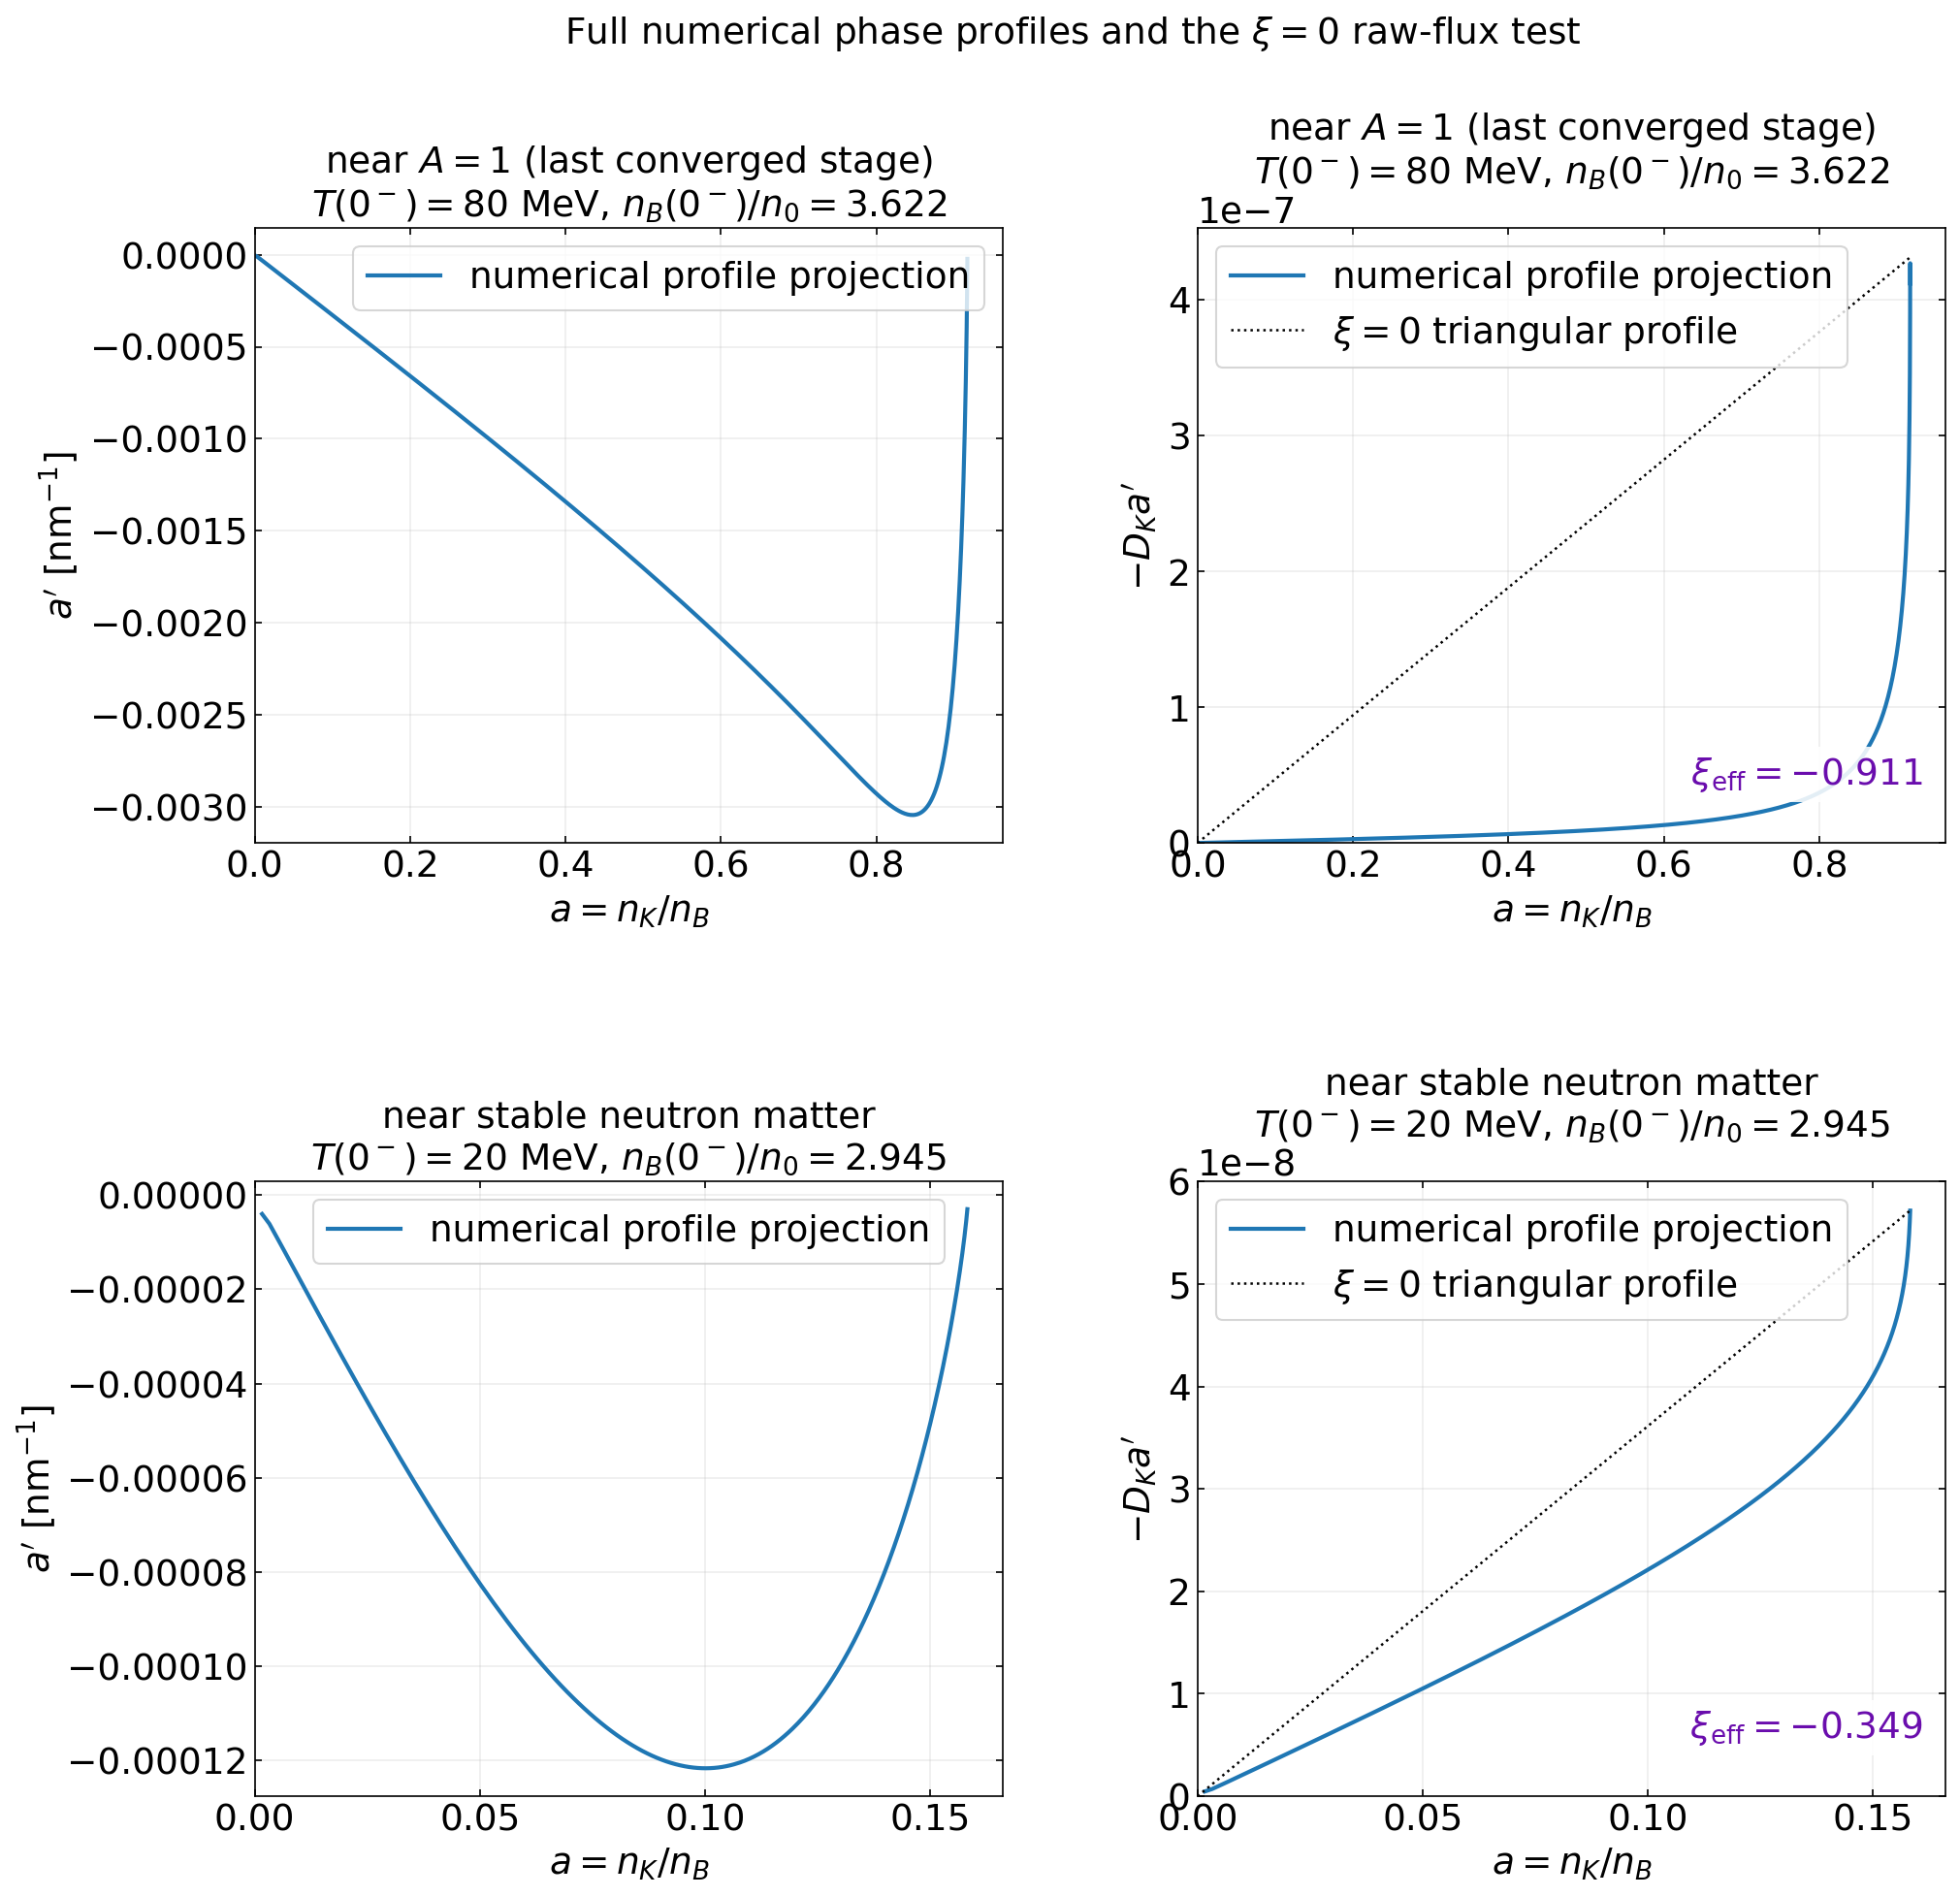

In [8]:
# Tunable plotting parameters
FIGURE_WIDTH = 15.0
FIGURE_HEIGHT_PER_ROW = 7.0
FIGURE_DPI = 150
EXPORT_DPI = 240
CONSTRAINED_LAYOUT = False
FIGURE_FACE_COLOR = "white"
AXES_FACE_COLOR = "white"
NUMERICAL_COLOR = "#1f77b4"
XI_ZERO_COLOR = "black"
NUMERICAL_LINE_STYLE = "-"
XI_ZERO_LINE_STYLE = ":"
PROFILE_LINE_WIDTH = 2.0
XI_ZERO_LINE_WIDTH = 1.2
GRID_ENABLED = True
GRID_ALPHA = 0.22
TITLE_FONT_SIZE = 18
SUPTITLE_FONT_SIZE = 18
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18
PHASE_LEGEND_LOCATION = "best"
FLUX_LEGEND_LOCATION = "upper left"
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
PHASE_X_MINIMUM = 0.0
PHASE_X_MARGIN_FACTOR = 1.05
FLUX_X_MINIMUM = 0.0
FLUX_X_MARGIN_FACTOR = 1.05
FLUX_Y_MINIMUM = 0.0
FLUX_Y_MARGIN_FACTOR = 1.05
XI_TEXT_POSITION = (0.97, 0.08)
XI_TEXT_COLOR = "#6a0dad"
XI_TEXT_FONT_SIZE = 18
XI_TEXT_HORIZONTAL_ALIGNMENT = "right"
XI_TEXT_VERTICAL_ALIGNMENT = "bottom"
XI_TEXT_BOX_FACE_COLOR = "white"
XI_TEXT_BOX_EDGE_COLOR = "none"
XI_TEXT_BOX_ALPHA = 0.88
SUBPLOT_HORIZONTAL_SPACE = 0.26
SUBPLOT_VERTICAL_SPACE = 0.55
SUPTITLE_Y = 0.985
OUTPUT_PNG = CACHE_DIR / "a-prime-and-diffusive-flux-phase-portraits.png"
OUTPUT_PDF = CACHE_DIR / "a-prime-and-diffusive-flux-phase-portraits.pdf"

plot_point_names = [name for name in sample_points if name in solver_results]
if not plot_point_names:
    raise RuntimeError("Run at least one solver-pair calculation cell before plotting")

fig, axes = plt.subplots(
    nrows=len(plot_point_names),
    ncols=2,
    figsize=(FIGURE_WIDTH, FIGURE_HEIGHT_PER_ROW * len(plot_point_names)),
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=FIGURE_FACE_COLOR,
)
axes = np.atleast_2d(axes)

solver_styles = {
    "uNmax": {
        "color": NUMERICAL_COLOR,
        "linestyle": NUMERICAL_LINE_STYLE,
        "label": "numerical profile projection",
    },
}

for row_index, point_name in enumerate(plot_point_names):
    point = resolved_points[point_name]
    phase_axis = axes[row_index, 0]
    flux_axis = axes[row_index, 1]
    phase_axis.set_facecolor(AXES_FACE_COLOR)
    flux_axis.set_facecolor(AXES_FACE_COLOR)

    for solver_name, style in solver_styles.items():
        diagnostics = phase_profiles[point_name][solver_name]
        resolved = diagnostics["resolved"]
        phase_order = np.argsort(diagnostics["a"][resolved])
        flux_order = np.argsort(diagnostics["a"][resolved])
        phase_axis.plot(
            diagnostics["a"][resolved][phase_order],
            diagnostics["a_prime_per_nm"][resolved][phase_order],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=PROFILE_LINE_WIDTH,
            label=style["label"],
        )
        flux_axis.plot(
            diagnostics["a"][resolved][flux_order],
            diagnostics["minus_D_a_prime"][resolved][flux_order],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=PROFILE_LINE_WIDTH,
            label=style["label"],
        )

    numerical_diagnostics = phase_profiles[point_name]["uNmax"]
    xi_zero_a = np.array([0.0, numerical_diagnostics["a_interface"]])
    xi_zero_flux = np.array([0.0, numerical_diagnostics["interface_flux"]])
    flux_axis.plot(
        xi_zero_a,
        xi_zero_flux,
        color=XI_ZERO_COLOR,
        linestyle=XI_ZERO_LINE_STYLE,
        linewidth=XI_ZERO_LINE_WIDTH,
        label=r"$\xi=0$ triangular profile",
    )
    numerical_xi = phase_profiles[point_name]["uNmax"]["xi_effective"]
    flux_axis.text(
        XI_TEXT_POSITION[0],
        XI_TEXT_POSITION[1],
        rf"$\xi_{{\rm eff}}={numerical_xi:.3f}$",
        transform=flux_axis.transAxes,
        color=XI_TEXT_COLOR,
        fontsize=XI_TEXT_FONT_SIZE,
        ha=XI_TEXT_HORIZONTAL_ALIGNMENT,
        va=XI_TEXT_VERTICAL_ALIGNMENT,
        bbox={
            "facecolor": XI_TEXT_BOX_FACE_COLOR,
            "edgecolor": XI_TEXT_BOX_EDGE_COLOR,
            "alpha": XI_TEXT_BOX_ALPHA,
        },
    )

    point_title = (
        rf"{point['label']}" + "\n" +
        rf"$T(0^-)={point['T_MeV']:g}$ MeV, "
        rf"$n_B(0^-)/n_0={point['nB_over_n0']:.3f}$"
    )
    phase_axis.set_title(point_title, fontsize=TITLE_FONT_SIZE)
    flux_axis.set_title(point_title, fontsize=TITLE_FONT_SIZE)
    phase_axis.set_xlim(
        PHASE_X_MINIMUM,
        PHASE_X_MARGIN_FACTOR * phase_profiles[point_name]["uNmax"]["a_interface"],
    )
    flux_axis.set_xlim(
        FLUX_X_MINIMUM,
        FLUX_X_MARGIN_FACTOR * phase_profiles[point_name]["uNmax"]["a_interface"],
    )
    flux_y_maximum = max(
        float(
            np.nanmax(
                phase_profiles[point_name]["uNmax"]["minus_D_a_prime"][
                    phase_profiles[point_name]["uNmax"]["resolved"]
                ]
            )
        ),
        phase_profiles[point_name]["uNmax"]["interface_flux"],
    )
    flux_axis.set_ylim(
        FLUX_Y_MINIMUM,
        FLUX_Y_MARGIN_FACTOR * flux_y_maximum,
    )
    phase_axis.set_xlabel(r"$a=n_K/n_B$", fontsize=AXIS_LABEL_FONT_SIZE)
    phase_axis.set_ylabel(r"$a'$ [nm$^{-1}$]", fontsize=AXIS_LABEL_FONT_SIZE)
    flux_axis.set_xlabel(r"$a=n_K/n_B$", fontsize=AXIS_LABEL_FONT_SIZE)
    flux_axis.set_ylabel(r"$-D_Ka'$", fontsize=AXIS_LABEL_FONT_SIZE)

    for axis in (phase_axis, flux_axis):
        axis.grid(GRID_ENABLED, alpha=GRID_ALPHA)
        axis.tick_params(
            labelsize=TICK_LABEL_FONT_SIZE,
            direction=TICK_DIRECTION,
            top=TICKS_TOP,
            right=TICKS_RIGHT,
        )
        axis.xaxis.get_offset_text().set_fontsize(TICK_LABEL_FONT_SIZE)
        axis.yaxis.get_offset_text().set_fontsize(TICK_LABEL_FONT_SIZE)
    phase_axis.legend(fontsize=LEGEND_FONT_SIZE, loc=PHASE_LEGEND_LOCATION)
    flux_axis.legend(fontsize=LEGEND_FONT_SIZE, loc=FLUX_LEGEND_LOCATION)

fig.suptitle(
    r"Full numerical phase profiles and the $\xi=0$ raw-flux test",
    fontsize=SUPTITLE_FONT_SIZE,
    y=SUPTITLE_Y,
)
fig.subplots_adjust(
    wspace=SUBPLOT_HORIZONTAL_SPACE,
    hspace=SUBPLOT_VERTICAL_SPACE,
)
fig.savefig(OUTPUT_PNG, dpi=EXPORT_DPI, facecolor=FIGURE_FACE_COLOR)
fig.savefig(OUTPUT_PDF, facecolor=FIGURE_FACE_COLOR)
plt.show()

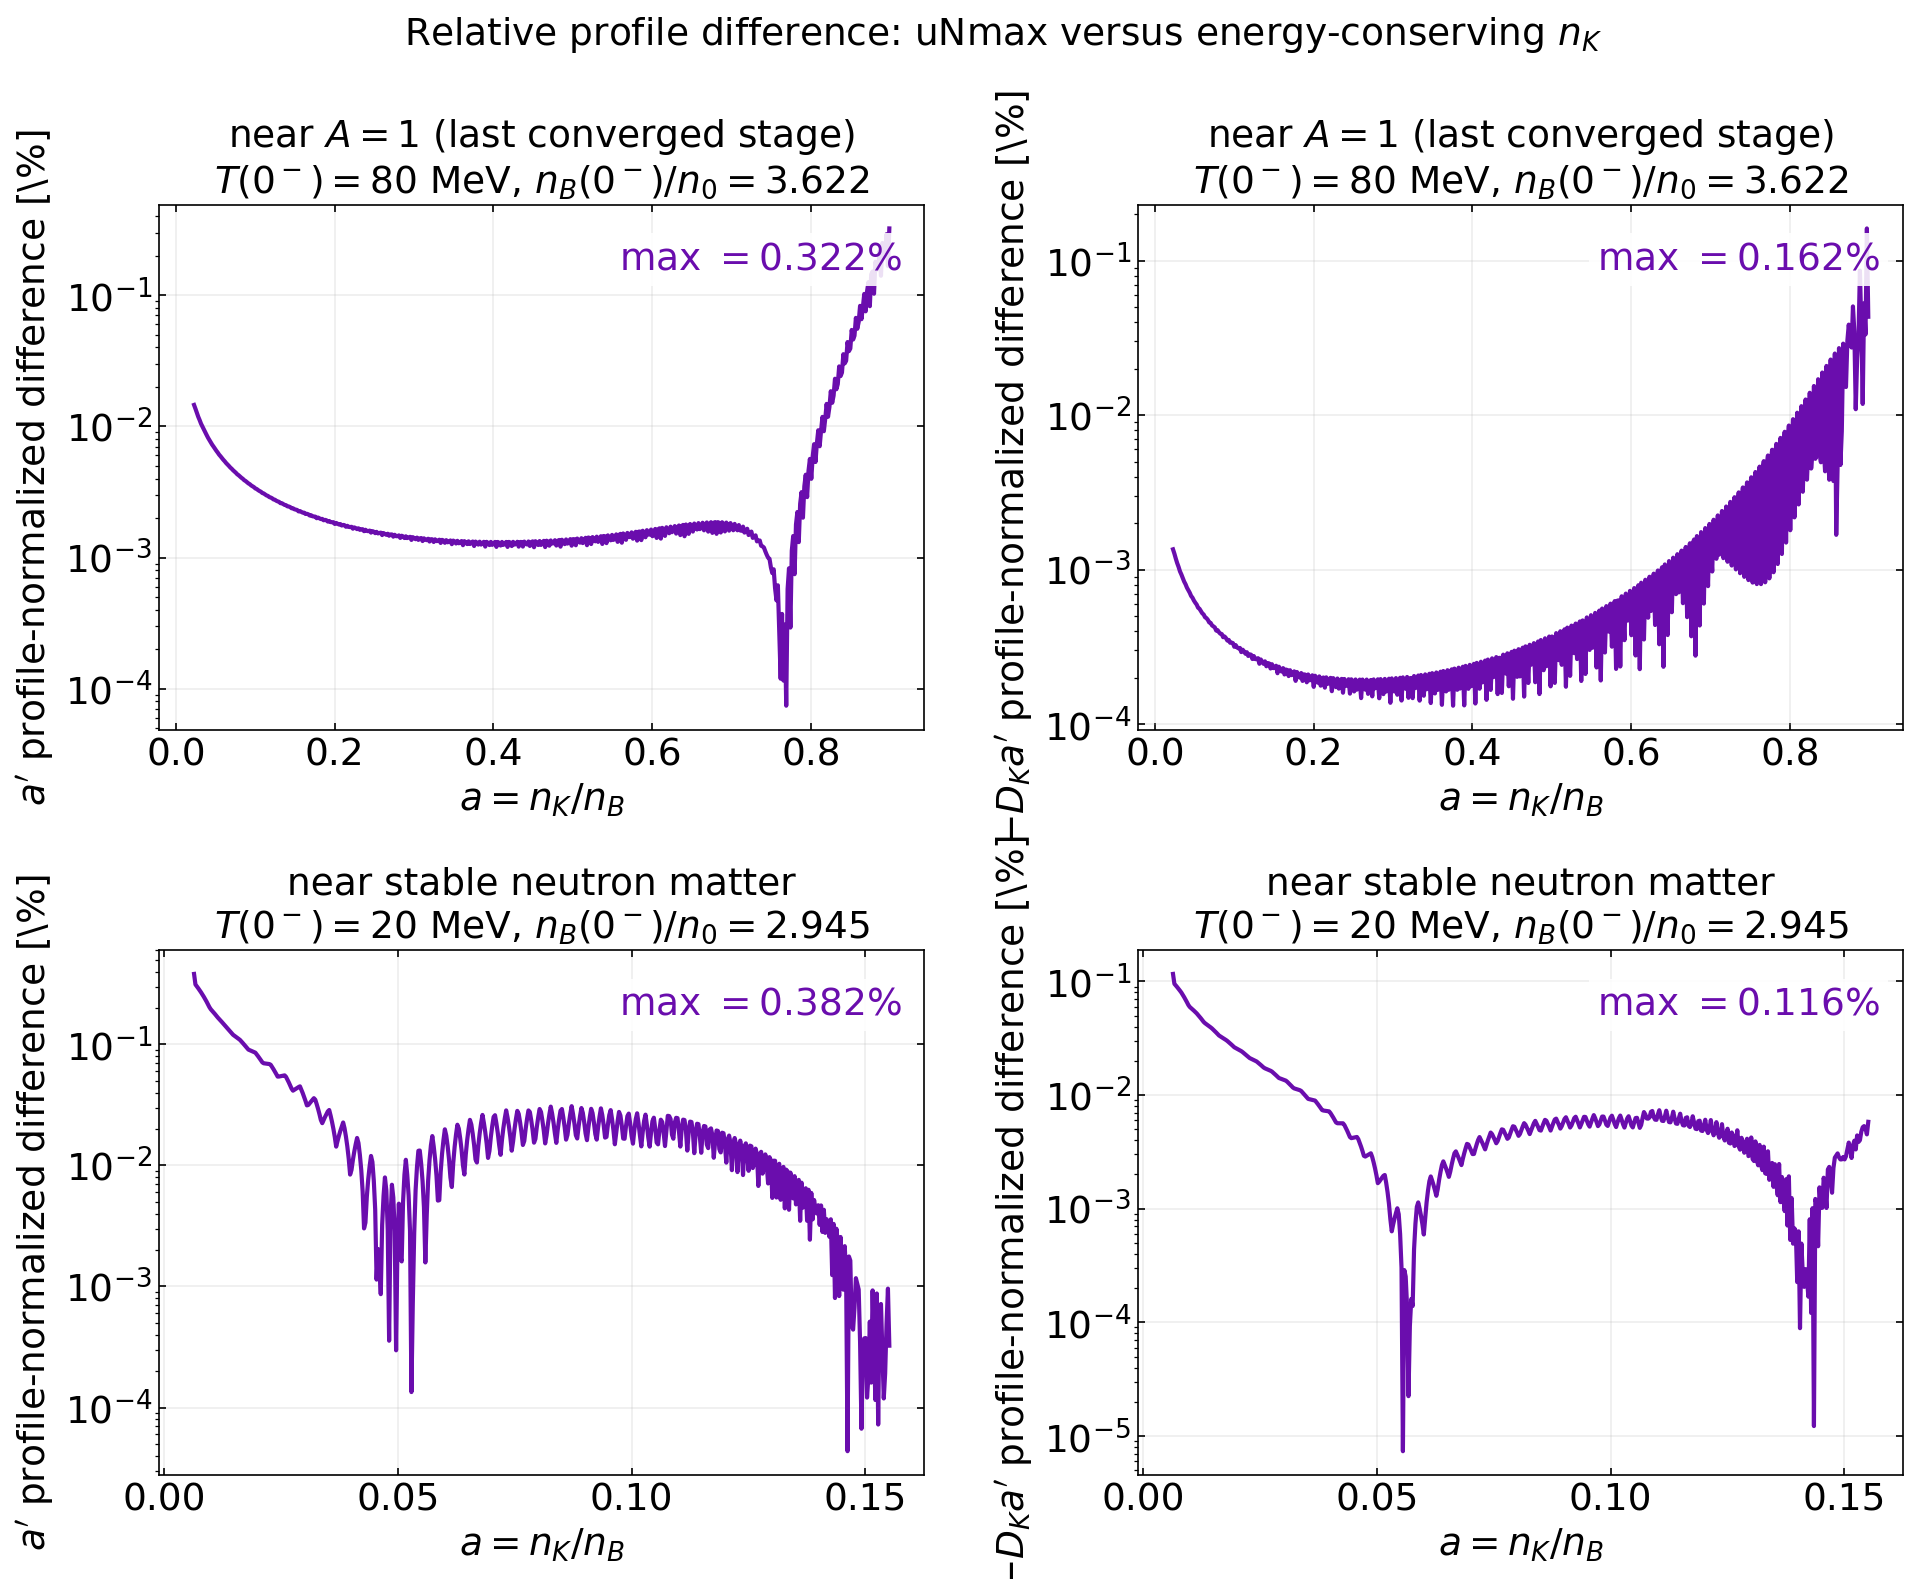

In [9]:
# Tunable plotting parameters
RELATIVE_FIGURE_WIDTH = 15.0
RELATIVE_FIGURE_HEIGHT_PER_ROW = 5.5
RELATIVE_FIGURE_DPI = 150
RELATIVE_EXPORT_DPI = 240
RELATIVE_FIGURE_FACE_COLOR = "white"
RELATIVE_AXES_FACE_COLOR = "white"
RELATIVE_COMMON_A_COUNT = 500
RELATIVE_ENDPOINT_TRIM_FRACTION = 0.02
RELATIVE_PLOT_FLOOR_PERCENT = 1.0e-10
RELATIVE_PERCENT_FACTOR = 100.0
RELATIVE_LINE_COLOR = "#6a0dad"
RELATIVE_LINE_STYLE = "-"
RELATIVE_LINE_WIDTH = 2.0
RELATIVE_Y_SCALE = "log"
RELATIVE_GRID_ENABLED = True
RELATIVE_GRID_ALPHA = 0.22
RELATIVE_TITLE_FONT_SIZE = 18
RELATIVE_SUPTITLE_FONT_SIZE = 18
RELATIVE_AXIS_LABEL_FONT_SIZE = 18
RELATIVE_TICK_LABEL_FONT_SIZE = 18
RELATIVE_ANNOTATION_FONT_SIZE = 18
RELATIVE_ANNOTATION_POSITION = (0.97, 0.93)
RELATIVE_ANNOTATION_HORIZONTAL_ALIGNMENT = "right"
RELATIVE_ANNOTATION_VERTICAL_ALIGNMENT = "top"
RELATIVE_ANNOTATION_BOX_FACE_COLOR = "white"
RELATIVE_ANNOTATION_BOX_EDGE_COLOR = "none"
RELATIVE_ANNOTATION_BOX_ALPHA = 0.88
RELATIVE_TICK_DIRECTION = "in"
RELATIVE_TICKS_TOP = True
RELATIVE_TICKS_RIGHT = True
RELATIVE_SUBPLOT_HORIZONTAL_SPACE = 0.28
RELATIVE_SUBPLOT_VERTICAL_SPACE = 0.42
RELATIVE_SUPTITLE_Y = 0.995
RELATIVE_OUTPUT_PNG = CACHE_DIR / "uNmax-vs-energy-nK-relative-profile-differences.png"
RELATIVE_OUTPUT_PDF = CACHE_DIR / "uNmax-vs-energy-nK-relative-profile-differences.pdf"


def common_profile_relative_difference(point_name, quantity):
    uNmax_profile = phase_profiles[point_name]["uNmax"]
    energy_nK_profile = phase_profiles[point_name]["energy_nK"]

    def sorted_unique_profile(profile):
        valid = profile["resolved"]
        a_values = np.asarray(profile["a"][valid], dtype=float)
        quantity_values = np.asarray(profile[quantity][valid], dtype=float)
        order = np.argsort(a_values)
        a_sorted = a_values[order]
        quantity_sorted = quantity_values[order]
        a_unique, unique_indices = np.unique(a_sorted, return_index=True)
        return a_unique, quantity_sorted[unique_indices]

    a_uNmax, quantity_uNmax = sorted_unique_profile(uNmax_profile)
    a_energy_nK, quantity_energy_nK = sorted_unique_profile(energy_nK_profile)
    common_a_minimum = max(float(a_uNmax[0]), float(a_energy_nK[0]))
    common_a_maximum = min(float(a_uNmax[-1]), float(a_energy_nK[-1]))
    common_a_span = common_a_maximum - common_a_minimum
    common_a = np.linspace(
        common_a_minimum + RELATIVE_ENDPOINT_TRIM_FRACTION * common_a_span,
        common_a_maximum - RELATIVE_ENDPOINT_TRIM_FRACTION * common_a_span,
        RELATIVE_COMMON_A_COUNT,
    )
    uNmax_projection = np.interp(common_a, a_uNmax, quantity_uNmax)
    energy_nK_projection = np.interp(common_a, a_energy_nK, quantity_energy_nK)
    profile_scale = max(
        float(np.max(np.abs(uNmax_projection))),
        float(np.max(np.abs(energy_nK_projection))),
        np.finfo(float).tiny,
    )
    relative_difference_percent = (
        RELATIVE_PERCENT_FACTOR
        * np.abs(uNmax_projection - energy_nK_projection)
        / profile_scale
    )
    return common_a, relative_difference_percent


relative_quantity_specs = (
    ("a_prime_per_nm", r"$a'$ profile-normalized difference [\%]"),
    ("minus_D_a_prime", r"$-D_Ka'$ profile-normalized difference [\%]"),
)
relative_figure, relative_axes = plt.subplots(
    nrows=len(plot_point_names),
    ncols=len(relative_quantity_specs),
    figsize=(
        RELATIVE_FIGURE_WIDTH,
        RELATIVE_FIGURE_HEIGHT_PER_ROW * len(plot_point_names),
    ),
    dpi=RELATIVE_FIGURE_DPI,
    facecolor=RELATIVE_FIGURE_FACE_COLOR,
)
relative_axes = np.atleast_2d(relative_axes)

for row_index, point_name in enumerate(plot_point_names):
    point = resolved_points[point_name]
    point_title = (
        rf"{point['label']}" + "\n" +
        rf"$T(0^-)={point['T_MeV']:g}$ MeV, "
        rf"$n_B(0^-)/n_0={point['nB_over_n0']:.3f}$"
    )
    for column_index, (quantity, y_label) in enumerate(relative_quantity_specs):
        relative_axis = relative_axes[row_index, column_index]
        relative_axis.set_facecolor(RELATIVE_AXES_FACE_COLOR)
        common_a, relative_difference_percent = common_profile_relative_difference(
            point_name,
            quantity,
        )
        plotted_difference = np.maximum(
            relative_difference_percent,
            RELATIVE_PLOT_FLOOR_PERCENT,
        )
        relative_axis.plot(
            common_a,
            plotted_difference,
            color=RELATIVE_LINE_COLOR,
            linestyle=RELATIVE_LINE_STYLE,
            linewidth=RELATIVE_LINE_WIDTH,
        )
        maximum_difference = float(np.max(relative_difference_percent))
        relative_axis.text(
            RELATIVE_ANNOTATION_POSITION[0],
            RELATIVE_ANNOTATION_POSITION[1],
            rf"max $={maximum_difference:.3g}\%$",
            transform=relative_axis.transAxes,
            color=RELATIVE_LINE_COLOR,
            fontsize=RELATIVE_ANNOTATION_FONT_SIZE,
            ha=RELATIVE_ANNOTATION_HORIZONTAL_ALIGNMENT,
            va=RELATIVE_ANNOTATION_VERTICAL_ALIGNMENT,
            bbox={
                "facecolor": RELATIVE_ANNOTATION_BOX_FACE_COLOR,
                "edgecolor": RELATIVE_ANNOTATION_BOX_EDGE_COLOR,
                "alpha": RELATIVE_ANNOTATION_BOX_ALPHA,
            },
        )
        relative_axis.set_title(point_title, fontsize=RELATIVE_TITLE_FONT_SIZE)
        relative_axis.set_xlabel(r"$a=n_K/n_B$", fontsize=RELATIVE_AXIS_LABEL_FONT_SIZE)
        relative_axis.set_ylabel(y_label, fontsize=RELATIVE_AXIS_LABEL_FONT_SIZE)
        relative_axis.set_yscale(RELATIVE_Y_SCALE)
        relative_axis.grid(RELATIVE_GRID_ENABLED, alpha=RELATIVE_GRID_ALPHA)
        relative_axis.tick_params(
            labelsize=RELATIVE_TICK_LABEL_FONT_SIZE,
            direction=RELATIVE_TICK_DIRECTION,
            top=RELATIVE_TICKS_TOP,
            right=RELATIVE_TICKS_RIGHT,
        )
        relative_axis.xaxis.get_offset_text().set_fontsize(RELATIVE_TICK_LABEL_FONT_SIZE)
        relative_axis.yaxis.get_offset_text().set_fontsize(RELATIVE_TICK_LABEL_FONT_SIZE)

relative_figure.suptitle(
    r"Relative profile difference: uNmax versus energy-conserving $n_K$",
    fontsize=RELATIVE_SUPTITLE_FONT_SIZE,
    y=RELATIVE_SUPTITLE_Y,
)
relative_figure.subplots_adjust(
    wspace=RELATIVE_SUBPLOT_HORIZONTAL_SPACE,
    hspace=RELATIVE_SUBPLOT_VERTICAL_SPACE,
)
relative_figure.savefig(
    RELATIVE_OUTPUT_PNG,
    dpi=RELATIVE_EXPORT_DPI,
    facecolor=RELATIVE_FIGURE_FACE_COLOR,
)
relative_figure.savefig(
    RELATIVE_OUTPUT_PDF,
    facecolor=RELATIVE_FIGURE_FACE_COLOR,
)
plt.show()


## Reading the result

- The main figure shows one **numerical profile projection**, taken from uNmax. The redundant overlaid energy-conserving $n_K$ curve has been removed.
- The left column is the phase portrait $a'(a)$. The right column directly plots $-D_Ka'$ against $a$; the black dotted line is the $\xi=0$ triangular profile.
- The separate comparison figure interpolates both numerical solutions onto their shared $a$ interval. It plots $100|y_{\rm uNmax}-y_{n_K}|/\max_a(|y_{\rm uNmax}|,|y_{n_K}|)$, so profile zeros do not create artificial ratio spikes. The comparison trims 2% from each endpoint because independently adapted meshes make one-sided derivative estimates unreliable there.
- A negative $\xi_{\rm eff}$ means that the diffusive flux stays small over most of the composition interval and rises late near the interface. Because the velocity denominator contains $1+\xi a_*$, this makes the full numerical velocity larger than the $\xi=0$ semi-analytical estimate, especially when $a_*$ is close to one.


## Cold-interface energy-conserving versus thermal-conducting profiles

This section compares the previous ideal energy-conserving absolute-$n_K$ front with the new Fourier thermal-conducting front at the same upstream state,

$$T_N=10\,\mathrm{MeV},\qquad n_{B,N}=3n_0,\qquad B^{1/4}=180\,\mathrm{MeV}.$$

For the ideal energy-conserving calculation, `solve_front_energy_conserving_uNmax` tunes $a(0^+)$ to the exact cold endpoint $T(0^+)=0$ while solving the absolute-$n_K$ profile. The notebook also attempts the redundant fixed-$a$ `solve_front_energy_conserving_nK` entry point; if that non-Lipschitz cold solve fails, the comparison uses the already-converged cold `uNmax` absolute-$n_K$ profile and reports the fallback explicitly. The thermal calculation independently solves its global BVP with the exact boundary condition $T(0^+)=0$; it does not inherit the ideal solver's interface composition or velocity.

The negative-$x$ segments show uniform upstream pure neutron matter. There $a=1$, $n_K=n_B$, and the hydrodynamic variables are constant. The neutron-matter EOS does not define $\mu_K$, so that upstream segment is deliberately left blank and annotated rather than assigned an artificial value.


In [10]:
# Physical inputs and numerical controls for the cold-interface comparison
TC_COMPARE_T_N_MEV = 10.0
TC_COMPARE_NB_OVER_N0 = 3.0
TC_COMPARE_B14_MEV = 180.0
TC_COMPARE_MS_MEV = 0.0
TC_COMPARE_NM_TYPE = "PNM"
TC_COMPARE_TAIL_EPS = 1.0e-8
TC_COMPARE_N_MESH = 200
TC_COMPARE_TOL_BVP = 1.0e-4
TC_COMPARE_MAX_NODES = 10000
TC_COMPARE_JB_BOUND_FACTOR = 100.0
TC_COMPARE_FORCE_RECOMPUTE = False
TC_COMPARE_CACHE_DIR = Path("local_analysis_results/26SU-10")
TC_COMPARE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

TC_COMPARE_NB_N = TC_COMPARE_NB_OVER_N0 * N0_MEV3
TC_COMPARE_TAG = "TN10-nB3n0-B180-tail1e-8"
TC_COMPARE_COLD_CACHE = TC_COMPARE_CACHE_DIR / f"cold-uNmax-{TC_COMPARE_TAG}.npy"
TC_COMPARE_ENERGY_CACHE = TC_COMPARE_CACHE_DIR / f"cold-energy-nK-{TC_COMPARE_TAG}.npy"
TC_COMPARE_THERMAL_CACHE = TC_COMPARE_CACHE_DIR / f"thermal-conducting-{TC_COMPARE_TAG}.npy"


def tc_compare_load_or_solve(label, cache_path, solve_callback):
    if cache_path.exists() and not TC_COMPARE_FORCE_RECOMPUTE:
        result = normalize_endpoint_result(np.load(cache_path, allow_pickle=True).item())
        print(f"{label}: loaded {cache_path}")
    else:
        started = time.monotonic()
        result = normalize_endpoint_result(solve_callback())
        result["notebook_elapsed_s"] = time.monotonic() - started
        np.save(cache_path, result, allow_pickle=True)
        print(
            f"{label}: success={bool(result.get('success', False))}, "
            f"elapsed={result['notebook_elapsed_s']:.1f} s, cached at {cache_path}"
        )
    if not bool(result.get("success", False)):
        raise RuntimeError(f"{label} failed: {result.get('message', '')}")
    return result


def tc_compare_solve_cold_calibration():
    return phase_velocity.solve_front_energy_conserving_uNmax(
        T_0minus=TC_COMPARE_T_N_MEV,
        nB_0minus=TC_COMPARE_NB_N,
        B_one_forth=TC_COMPARE_B14_MEV,
        T_0plus=0.0,
        ms=TC_COMPARE_MS_MEV,
        param=para.paraQMCRMF3,
        NM_type=TC_COMPARE_NM_TYPE,
        tail_eps=TC_COMPARE_TAIL_EPS,
        n_mesh=TC_COMPARE_N_MESH,
        tol_bvp=TC_COMPARE_TOL_BVP,
        max_nodes=TC_COMPARE_MAX_NODES,
        return_profile=True,
        verb=False,
    )


tc_compare_cold_calibration = tc_compare_load_or_solve(
    "cold energy calibration",
    TC_COMPARE_COLD_CACHE,
    tc_compare_solve_cold_calibration,
)
TC_COMPARE_COLD_AQSTAR = float(tc_compare_cold_calibration["a_0plus_derived"])
TC_COMPARE_COLD_JB = float(tc_compare_cold_calibration["jB"])
TC_COMPARE_JB_BOUNDS = (
    TC_COMPARE_COLD_JB / TC_COMPARE_JB_BOUND_FACTOR,
    TC_COMPARE_COLD_JB * TC_COMPARE_JB_BOUND_FACTOR,
)
if float(tc_compare_cold_calibration["T_profile"][0]) != 0.0:
    raise RuntimeError("cold calibration did not reach exact T(0+)=0")


def tc_compare_solve_energy_nK():
    return phase_velocity.solve_front_energy_conserving_nK(
        T_0minus=TC_COMPARE_T_N_MEV,
        nB_0minus=TC_COMPARE_NB_N,
        B_one_forth=TC_COMPARE_B14_MEV,
        a_0plus=TC_COMPARE_COLD_AQSTAR,
        ms=TC_COMPARE_MS_MEV,
        param=para.paraQMCRMF3,
        NM_type=TC_COMPARE_NM_TYPE,
        tail_eps=TC_COMPARE_TAIL_EPS,
        compact_scale=float(tc_compare_cold_calibration["kappa"]),
        n_mesh=TC_COMPARE_N_MESH,
        tol_bvp=TC_COMPARE_TOL_BVP,
        max_nodes=TC_COMPARE_MAX_NODES,
        jB_guess=TC_COMPARE_COLD_JB,
        jB_bounds=TC_COMPARE_JB_BOUNDS,
        return_profile=True,
        return_raw_bvp_grid=False,
        verb=False,
    )


def tc_compare_solve_thermal():
    return phase_velocity.solve_front_thermal_conducting(
        T_0minus=TC_COMPARE_T_N_MEV,
        nB_0minus=TC_COMPARE_NB_N,
        B_one_forth=TC_COMPARE_B14_MEV,
        T_0plus=0.0,
        ms=TC_COMPARE_MS_MEV,
        param=para.paraQMCRMF3,
        NM_type=TC_COMPARE_NM_TYPE,
        tail_eps=TC_COMPARE_TAIL_EPS,
        n_mesh=TC_COMPARE_N_MESH,
        tol_bvp=TC_COMPARE_TOL_BVP,
        max_nodes=TC_COMPARE_MAX_NODES,
        return_profile=True,
        verb=False,
    )


try:
    tc_compare_energy_result = tc_compare_load_or_solve(
        "fixed-a energy-conserving nK",
        TC_COMPARE_ENERGY_CACHE,
        tc_compare_solve_energy_nK,
    )
    tc_compare_energy_profile_source = "solve_front_energy_conserving_nK"
except RuntimeError as fixed_a_error:
    warnings.warn(
        "The redundant fixed-a cold solve failed; using the converged cold "
        "uNmax absolute-nK profile. Details: " + str(fixed_a_error)
    )
    tc_compare_energy_result = dict(tc_compare_cold_calibration)
    tc_compare_energy_profile_source = "solve_front_energy_conserving_uNmax_TQstar0"
tc_compare_thermal_result = tc_compare_load_or_solve(
    "thermal-conducting",
    TC_COMPARE_THERMAL_CACHE,
    tc_compare_solve_thermal,
)
if float(tc_compare_energy_result["T_profile"][0]) != 0.0:
    raise RuntimeError("energy-conserving nK profile is not exactly cold at x=0+")
if float(tc_compare_thermal_result["T_profile"][0]) != 0.0:
    raise RuntimeError("thermal-conducting profile is not exactly cold at x=0+")
print(f"cold ideal a(0+) = {TC_COMPARE_COLD_AQSTAR:.10f}")
print(f"thermal-selected a(0+) = {float(tc_compare_thermal_result['a_0plus']):.10f}")


cold energy calibration: loaded local_analysis_results/26SU-10/cold-uNmax-TN10-nB3n0-B180-tail1e-8.npy
fixed-a energy-conserving nK: loaded local_analysis_results/26SU-10/cold-energy-nK-TN10-nB3n0-B180-tail1e-8.npy
thermal-conducting: loaded local_analysis_results/26SU-10/thermal-conducting-TN10-nB3n0-B180-tail1e-8.npy
cold ideal a(0+) = 0.5506570145
thermal-selected a(0+) = 0.5916454053


/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_56470/3318876926.py:122: UserWarning: The redundant fixed-a cold solve failed; using the converged cold uNmax absolute-nK profile. Details: fixed-a energy-conserving nK failed: The maximum number of mesh nodes is exceeded.; last failure: The solution converged.; best scaled residual=1.420e-07; continuation failed at aQstar=0.02: A singular Jacobian encountered when solving the collocation system.; last failure: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.; best scaled residual=3.057e-01
  warnings.warn(


In [11]:
def tc_compare_quark_pressure(muB, muK, temperature):
    return np.asarray(
        [
            phase_velocity.PQM(
                float(muB_value),
                float(muK_value),
                TC_COMPARE_B14_MEV,
                float(temperature_value),
                ms=TC_COMPARE_MS_MEV,
            )
            for muB_value, muK_value, temperature_value in zip(muB, muK, temperature)
        ],
        dtype=float,
    )


def tc_compare_energy_profile(result):
    return {
        "x_nm": np.asarray(result["x"], dtype=float) * const.MeV_fm / 1.0e6,
        "a": np.asarray(result["a"], dtype=float),
        "u_m_s": np.asarray(result["u"], dtype=float) * const.m_per_sec,
        "T_MeV": np.asarray(result["T_profile"], dtype=float),
        "muB_MeV": np.asarray(result["muB"], dtype=float),
        "nB_over_n0": np.asarray(result["nB"], dtype=float) / N0_MEV3,
        "P_MeV_fm3": np.asarray(result["P_profile"], dtype=float) / const.MeV_fm**3,
        "muK_MeV": np.asarray(result["muK"], dtype=float),
        "nK_over_n0": np.asarray(result["nK"], dtype=float) / N0_MEV3,
    }


def tc_compare_thermal_profile(result):
    muB = np.asarray(result["muB_profile"], dtype=float)
    muK = np.asarray(result["muK_profile"], dtype=float)
    temperature = np.asarray(result["T_profile"], dtype=float)
    nB = np.asarray(result["nB_profile"], dtype=float)
    nK = np.asarray(result["nK_profile"], dtype=float)
    return {
        "x_nm": np.asarray(result["x"], dtype=float) * const.MeV_fm / 1.0e6,
        "a": nK / nB,
        "u_m_s": np.asarray(result["u_profile"], dtype=float) * const.m_per_sec,
        "T_MeV": temperature,
        "muB_MeV": muB,
        "nB_over_n0": nB / N0_MEV3,
        "P_MeV_fm3": tc_compare_quark_pressure(muB, muK, temperature) / const.MeV_fm**3,
        "muK_MeV": muK,
        "nK_over_n0": nK / N0_MEV3,
    }


tc_compare_profiles = {
    "energy": tc_compare_energy_profile(tc_compare_energy_result),
    "thermal": tc_compare_thermal_profile(tc_compare_thermal_result),
}
for solver_name, profile in tc_compare_profiles.items():
    shapes = {np.asarray(values).shape for values in profile.values()}
    if len(shapes) != 1:
        raise RuntimeError(f"{solver_name} comparison arrays have inconsistent shapes: {shapes}")
    if not all(np.all(np.isfinite(values)) for values in profile.values()):
        raise RuntimeError(f"{solver_name} comparison profile contains non-finite values")

TC_COMPARE_P_N = float(
    phase_velocity.PNM_n(
        TC_COMPARE_NB_N,
        TC_COMPARE_T_N_MEV,
        param=para.paraQMCRMF3,
        NM_type=TC_COMPARE_NM_TYPE,
    )
)
TC_COMPARE_MUB_N = float(
    phase_velocity.muB_from_nB_physical(
        TC_COMPARE_NB_N,
        TC_COMPARE_T_N_MEV,
        param=para.paraQMCRMF3,
        NM_type=TC_COMPARE_NM_TYPE,
        auto_expand=True,
    )
)
tc_compare_upstream = {
    "energy": {
        "a": 1.0,
        "u_m_s": float(tc_compare_energy_result["u_0minus"]) * const.m_per_sec,
        "T_MeV": TC_COMPARE_T_N_MEV,
        "muB_MeV": TC_COMPARE_MUB_N,
        "nB_over_n0": TC_COMPARE_NB_OVER_N0,
        "P_MeV_fm3": TC_COMPARE_P_N / const.MeV_fm**3,
        "muK_MeV": np.nan,
        "nK_over_n0": TC_COMPARE_NB_OVER_N0,
    },
    "thermal": {
        "a": 1.0,
        "u_m_s": float(tc_compare_thermal_result["u_0minus"]) * const.m_per_sec,
        "T_MeV": TC_COMPARE_T_N_MEV,
        "muB_MeV": TC_COMPARE_MUB_N,
        "nB_over_n0": TC_COMPARE_NB_OVER_N0,
        "P_MeV_fm3": TC_COMPARE_P_N / const.MeV_fm**3,
        "muK_MeV": np.nan,
        "nK_over_n0": TC_COMPARE_NB_OVER_N0,
    },
}

tc_compare_summary = pd.DataFrame(
    [
        {
            "solver": "ideal energy-conserving nK",
            "profile source": tc_compare_energy_profile_source,
            "u_N [m/s]": tc_compare_upstream["energy"]["u_m_s"],
            "a(0+)": float(tc_compare_energy_result["a_0plus_derived"]),
            "T(0+) [MeV]": float(tc_compare_energy_result["T_profile"][0]),
            "T_Q [MeV]": float(tc_compare_energy_result["T_inf"]),
            "x_end [nm]": float(tc_compare_profiles["energy"]["x_nm"][-1]),
            "BVP nodes": int(tc_compare_energy_result.get("bvp_nodes", -1)),
        },
        {
            "solver": "thermal conducting",
            "profile source": "solve_front_thermal_conducting",
            "u_N [m/s]": tc_compare_upstream["thermal"]["u_m_s"],
            "a(0+)": float(tc_compare_thermal_result["a_0plus"]),
            "T(0+) [MeV]": float(tc_compare_thermal_result["T_profile"][0]),
            "T_Q [MeV]": float(tc_compare_thermal_result["T_inf"]),
            "x_end [nm]": float(tc_compare_profiles["thermal"]["x_nm"][-1]),
            "BVP nodes": int(tc_compare_thermal_result.get("bvp_nodes", -1)),
        },
    ]
)
display(tc_compare_summary)


,solver,profile source,u_N [m/s],a(0+),T(0+) [MeV],T_Q [MeV],x_end [nm],BVP nodes
0,ideal energy-conserving nK,solve_front_energy_conserving_uNmax_TQstar0,248.558076,0.550657,0.0,31.82403,2576.558206,3015
1,thermal conducting,solve_front_thermal_conducting,223.990630,0.591645,0.0,31.82403,2386.580265,201


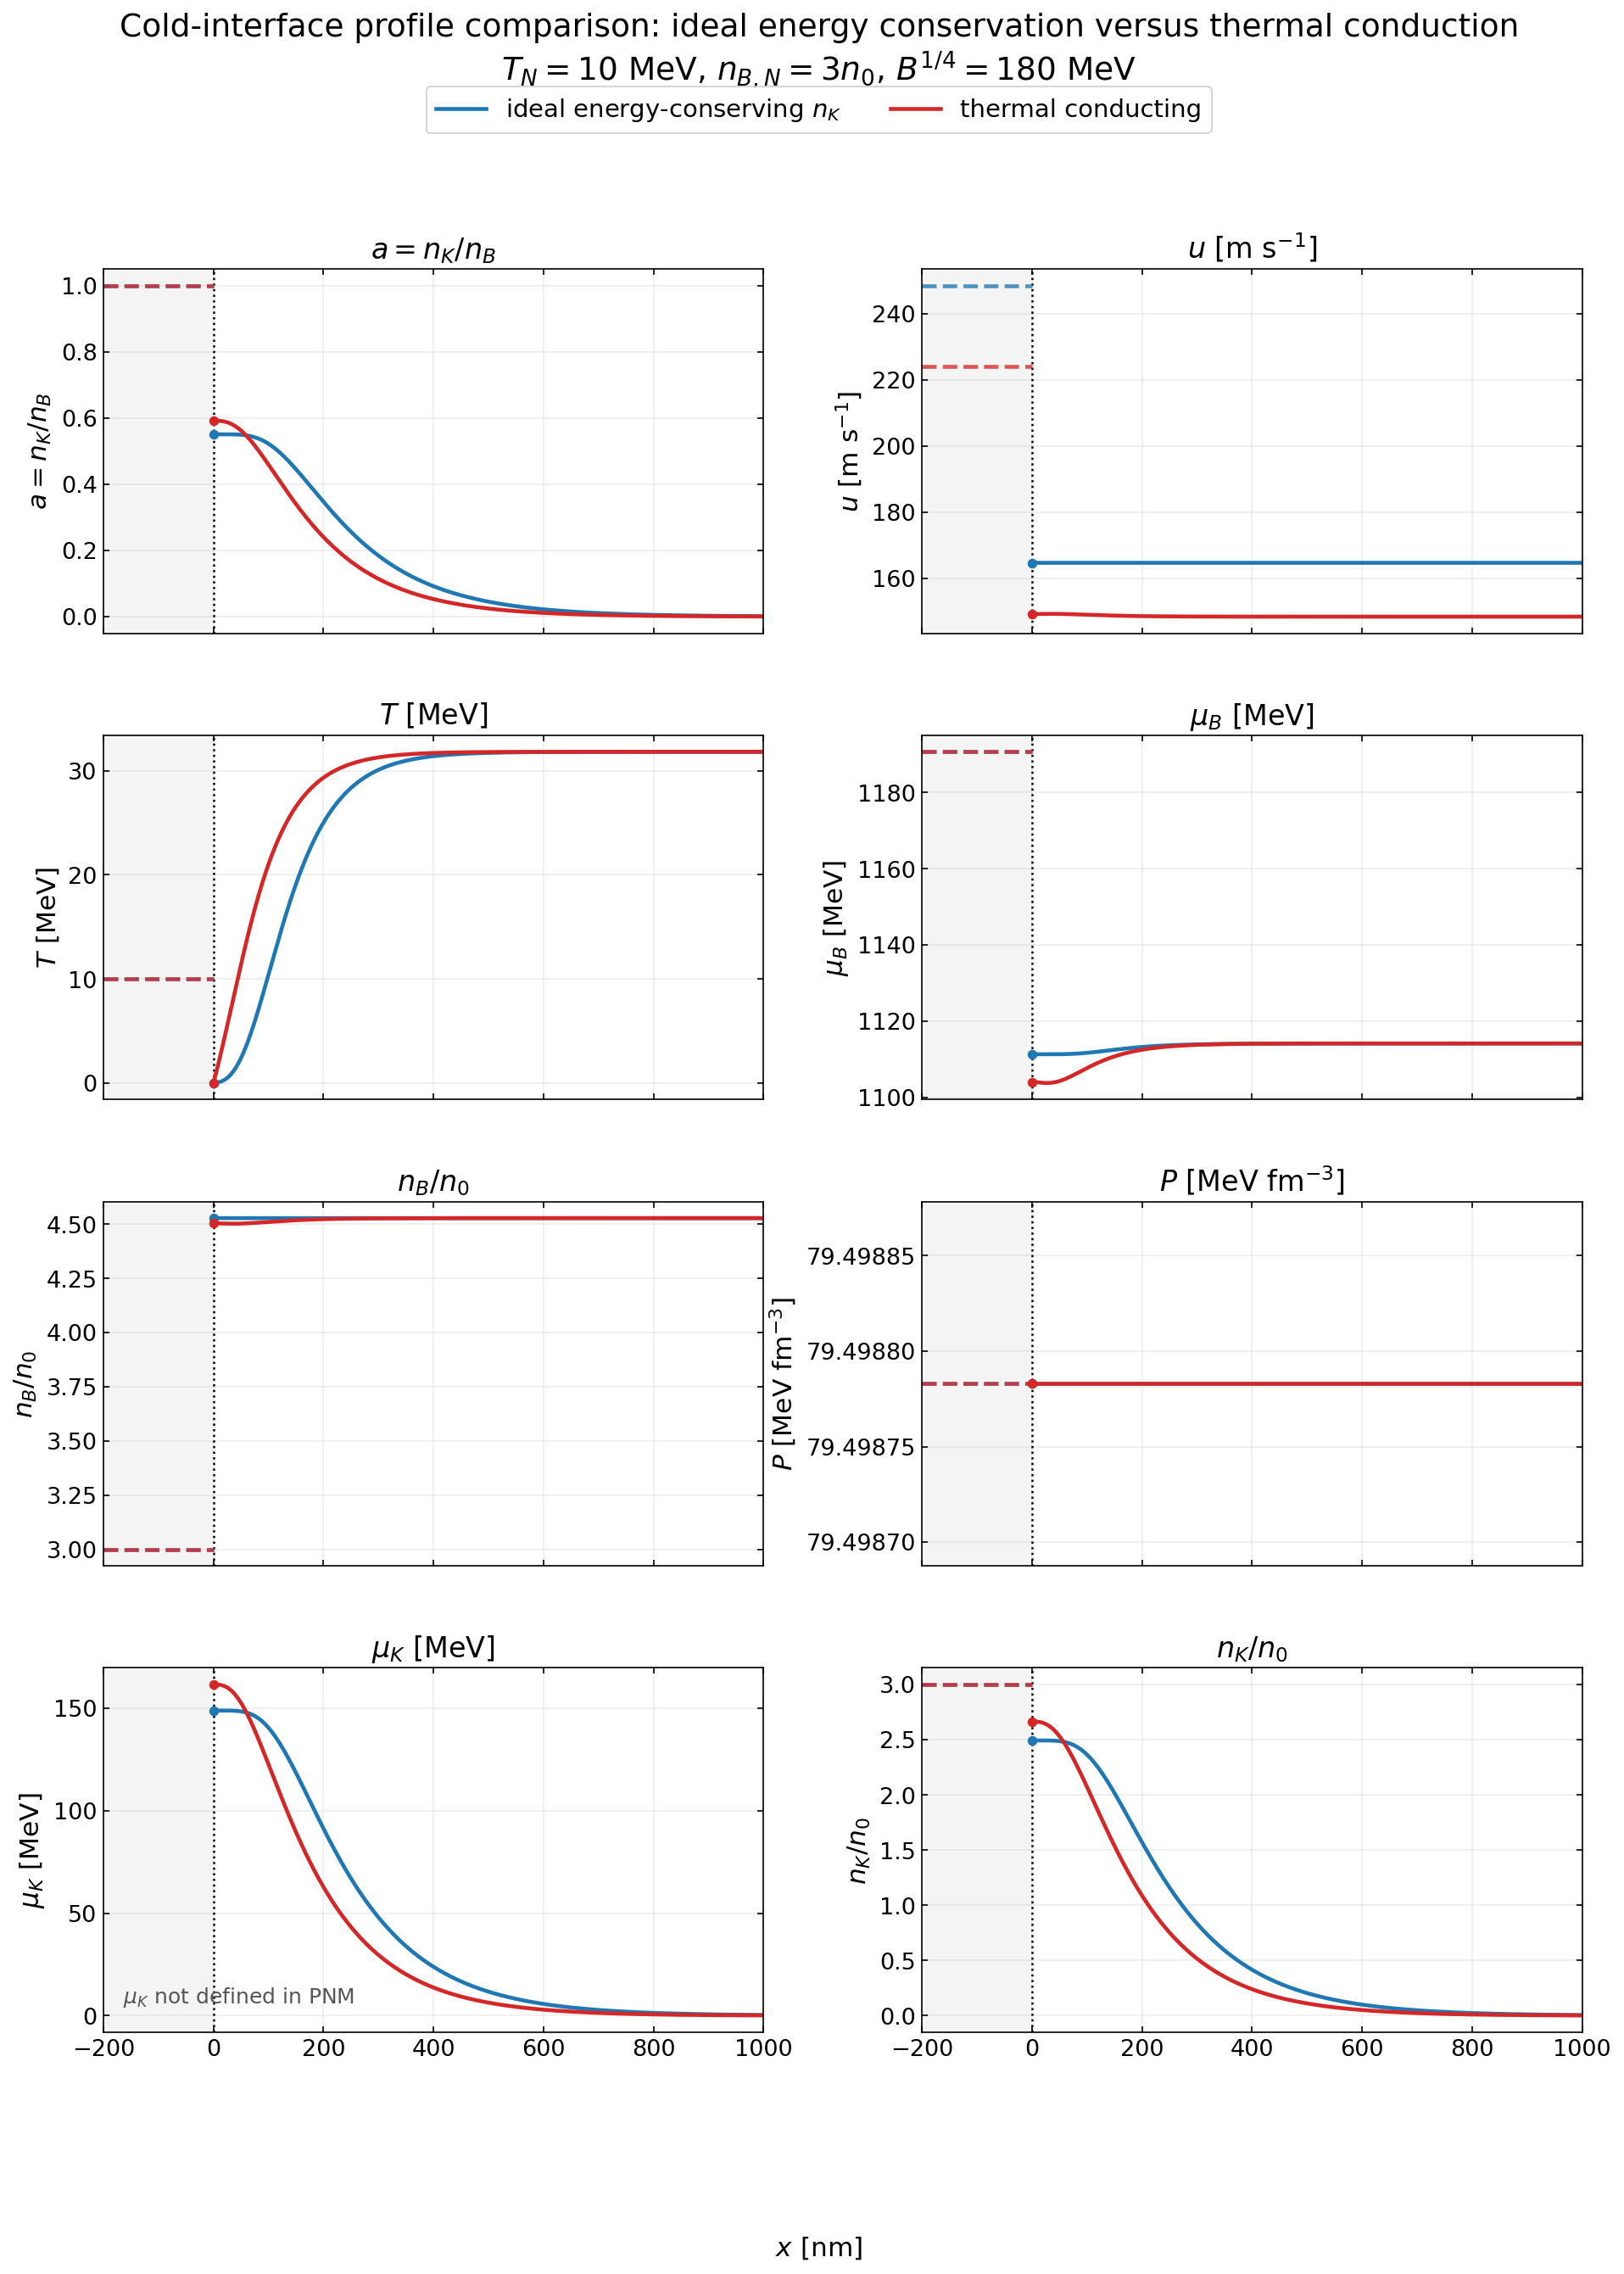

saved /Users/janshao/NSM_related/local_analysis_results/26SU-10/cold-energy-nK-vs-thermal-profiles.png
saved /Users/janshao/NSM_related/local_analysis_results/26SU-10/cold-energy-nK-vs-thermal-profiles.pdf


In [12]:
# Tunable plotting parameters
TC_PLOT_NROWS = 4
TC_PLOT_NCOLS = 2
TC_PLOT_FIGURE_SIZE = (15.0, 18.0)
TC_PLOT_FIGURE_DPI = 150
TC_PLOT_EXPORT_DPI = 240
TC_PLOT_FIGURE_FACE_COLOR = "white"
TC_PLOT_AXES_FACE_COLOR = "white"
TC_PLOT_CONSTRAINED_LAYOUT = False
TC_PLOT_SHARE_X = True
TC_PLOT_PROFILE_SPECS = (
    ("a", r"$a=n_K/n_B$"),
    ("u_m_s", r"$u$ [m s$^{-1}$]"),
    ("T_MeV", r"$T$ [MeV]"),
    ("muB_MeV", r"$\mu_B$ [MeV]"),
    ("nB_over_n0", r"$n_B/n_0$"),
    ("P_MeV_fm3", r"$P$ [MeV fm$^{-3}$]"),
    ("muK_MeV", r"$\mu_K$ [MeV]"),
    ("nK_over_n0", r"$n_K/n_0$"),
)
TC_PLOT_SOLVER_STYLES = {
    "energy": {"color": "#1f77b4", "label": r"ideal energy-conserving $n_K$"},
    "thermal": {"color": "#d62728", "label": "thermal conducting"},
}
TC_PLOT_DOWNSTREAM_LINE_STYLE = "-"
TC_PLOT_UPSTREAM_LINE_STYLE = "--"
TC_PLOT_PROFILE_LINE_WIDTH = 2.2
TC_PLOT_UPSTREAM_ALPHA = 0.78
TC_PLOT_INTERFACE_MARKER = "o"
TC_PLOT_INTERFACE_MARKER_SIZE = 4.5
TC_PLOT_INTERFACE_MARKER_LINE_STYLE = "none"
TC_PLOT_UPSTREAM_SHADE_COLOR = "#d9d9d9"
TC_PLOT_UPSTREAM_SHADE_ALPHA = 0.28
TC_PLOT_UPSTREAM_SHADE_LINE_WIDTH = 0.0
TC_PLOT_BOUNDARY_COLOR = "black"
TC_PLOT_BOUNDARY_LINE_STYLE = ":"
TC_PLOT_BOUNDARY_LINE_WIDTH = 1.2
TC_PLOT_GRID_ENABLED = True
TC_PLOT_GRID_ALPHA = 0.22
TC_PLOT_X_SCALE = "linear"
TC_PLOT_SYMLOG_SCALE_NAME = "symlog"
TC_PLOT_X_LINTHRESH_NM = 10.0
TC_PLOT_X_MIN_NM = -200.0
TC_PLOT_X_MAX_NM = 1000.0
TC_PLOT_UPSTREAM_POINTS = 160
TC_PLOT_TITLE_FONT_SIZE = 16
TC_PLOT_SUPTITLE_FONT_SIZE = 18
TC_PLOT_AXIS_LABEL_FONT_SIZE = 15
TC_PLOT_TICK_LABEL_FONT_SIZE = 13
TC_PLOT_LEGEND_FONT_SIZE = 14
TC_PLOT_ANNOTATION_FONT_SIZE = 12
TC_PLOT_LEGEND_LOCATION = "upper center"
TC_PLOT_LEGEND_COLUMNS = 2
TC_PLOT_LEGEND_BBOX = (0.5, 0.965)
TC_PLOT_MUK_ANNOTATION_POSITION = (0.03, 0.08)
TC_PLOT_MUK_ANNOTATION_TEXT = r"$\mu_K$ not defined in PNM"
TC_PLOT_MUK_ANNOTATION_COLOR = "#555555"
TC_PLOT_PRESSURE_MIN_RELATIVE_SPAN = 1.0e-6
TC_PLOT_PRESSURE_RANGE_MARGIN_FACTOR = 1.2
TC_PLOT_PRESSURE_TICK_STYLE = "plain"
TC_PLOT_PRESSURE_USE_OFFSET = False
TC_PLOT_TICK_DIRECTION = "in"
TC_PLOT_TICKS_TOP = True
TC_PLOT_TICKS_RIGHT = True
TC_PLOT_SUBPLOT_HORIZONTAL_SPACE = 0.24
TC_PLOT_SUBPLOT_VERTICAL_SPACE = 0.28
TC_PLOT_SUPTITLE_Y = 0.992
TC_PLOT_SHARED_X_LABEL = r"$x$ [nm]"
TC_PLOT_BBOX_INCHES = "tight"
TC_PLOT_OUTPUT_PNG = TC_COMPARE_CACHE_DIR / "cold-energy-nK-vs-thermal-profiles.png"
TC_PLOT_OUTPUT_PDF = TC_COMPARE_CACHE_DIR / "cold-energy-nK-vs-thermal-profiles.pdf"

tc_plot_x_left_nm = TC_PLOT_X_MIN_NM
tc_plot_x_right_nm = TC_PLOT_X_MAX_NM
tc_plot_upstream_x_nm = np.linspace(
    tc_plot_x_left_nm,
    0.0,
    TC_PLOT_UPSTREAM_POINTS,
)

tc_plot_figure, tc_plot_axes = plt.subplots(
    nrows=TC_PLOT_NROWS,
    ncols=TC_PLOT_NCOLS,
    figsize=TC_PLOT_FIGURE_SIZE,
    dpi=TC_PLOT_FIGURE_DPI,
    sharex=TC_PLOT_SHARE_X,
    constrained_layout=TC_PLOT_CONSTRAINED_LAYOUT,
    facecolor=TC_PLOT_FIGURE_FACE_COLOR,
)
tc_plot_axes = np.asarray(tc_plot_axes).ravel()
tc_plot_legend_handles = []
tc_plot_legend_labels = []

for panel_index, (quantity, y_label) in enumerate(TC_PLOT_PROFILE_SPECS):
    axis = tc_plot_axes[panel_index]
    axis.set_facecolor(TC_PLOT_AXES_FACE_COLOR)
    axis.axvspan(
        tc_plot_x_left_nm,
        0.0,
        color=TC_PLOT_UPSTREAM_SHADE_COLOR,
        alpha=TC_PLOT_UPSTREAM_SHADE_ALPHA,
        linewidth=TC_PLOT_UPSTREAM_SHADE_LINE_WIDTH,
    )
    axis.axvline(
        0.0,
        color=TC_PLOT_BOUNDARY_COLOR,
        linestyle=TC_PLOT_BOUNDARY_LINE_STYLE,
        linewidth=TC_PLOT_BOUNDARY_LINE_WIDTH,
    )
    for solver_name, style in TC_PLOT_SOLVER_STYLES.items():
        profile = tc_compare_profiles[solver_name]
        downstream_line, = axis.plot(
            profile["x_nm"],
            profile[quantity],
            color=style["color"],
            linestyle=TC_PLOT_DOWNSTREAM_LINE_STYLE,
            linewidth=TC_PLOT_PROFILE_LINE_WIDTH,
            label=style["label"],
        )
        axis.plot(
            [0.0],
            [float(profile[quantity][0])],
            color=style["color"],
            marker=TC_PLOT_INTERFACE_MARKER,
            markersize=TC_PLOT_INTERFACE_MARKER_SIZE,
            linestyle=TC_PLOT_INTERFACE_MARKER_LINE_STYLE,
        )
        upstream_value = tc_compare_upstream[solver_name][quantity]
        if np.isfinite(upstream_value):
            axis.plot(
                tc_plot_upstream_x_nm,
                np.full_like(tc_plot_upstream_x_nm, upstream_value, dtype=float),
                color=style["color"],
                linestyle=TC_PLOT_UPSTREAM_LINE_STYLE,
                linewidth=TC_PLOT_PROFILE_LINE_WIDTH,
                alpha=TC_PLOT_UPSTREAM_ALPHA,
            )
        if panel_index == 0:
            tc_plot_legend_handles.append(downstream_line)
            tc_plot_legend_labels.append(style["label"])
    if quantity == "muK_MeV":
        axis.text(
            TC_PLOT_MUK_ANNOTATION_POSITION[0],
            TC_PLOT_MUK_ANNOTATION_POSITION[1],
            TC_PLOT_MUK_ANNOTATION_TEXT,
            transform=axis.transAxes,
            color=TC_PLOT_MUK_ANNOTATION_COLOR,
            fontsize=TC_PLOT_ANNOTATION_FONT_SIZE,
        )
    axis.set_title(y_label, fontsize=TC_PLOT_TITLE_FONT_SIZE)
    axis.set_ylabel(y_label, fontsize=TC_PLOT_AXIS_LABEL_FONT_SIZE)
    if TC_PLOT_X_SCALE == TC_PLOT_SYMLOG_SCALE_NAME:
        axis.set_xscale(TC_PLOT_X_SCALE, linthresh=TC_PLOT_X_LINTHRESH_NM)
    else:
        axis.set_xscale(TC_PLOT_X_SCALE)
    axis.set_xlim(tc_plot_x_left_nm, tc_plot_x_right_nm)
    if quantity == "P_MeV_fm3":
        pressure_values = np.concatenate(
            [
                np.asarray(profile[quantity], dtype=float)
                for profile in tc_compare_profiles.values()
            ]
            + [
                np.asarray(
                    [tc_compare_upstream[name][quantity]],
                    dtype=float,
                )
                for name in TC_PLOT_SOLVER_STYLES
            ]
        )
        pressure_center = float(np.mean(pressure_values))
        pressure_half_span = max(
            0.5 * float(np.ptp(pressure_values)),
            TC_PLOT_PRESSURE_MIN_RELATIVE_SPAN * abs(pressure_center),
        )
        pressure_half_span *= TC_PLOT_PRESSURE_RANGE_MARGIN_FACTOR
        axis.set_ylim(
            pressure_center - pressure_half_span,
            pressure_center + pressure_half_span,
        )
        axis.ticklabel_format(
            axis="y",
            style=TC_PLOT_PRESSURE_TICK_STYLE,
            useOffset=TC_PLOT_PRESSURE_USE_OFFSET,
        )
    axis.grid(TC_PLOT_GRID_ENABLED, alpha=TC_PLOT_GRID_ALPHA)
    axis.tick_params(
        labelsize=TC_PLOT_TICK_LABEL_FONT_SIZE,
        direction=TC_PLOT_TICK_DIRECTION,
        top=TC_PLOT_TICKS_TOP,
        right=TC_PLOT_TICKS_RIGHT,
    )
    axis.xaxis.get_offset_text().set_fontsize(TC_PLOT_TICK_LABEL_FONT_SIZE)
    axis.yaxis.get_offset_text().set_fontsize(TC_PLOT_TICK_LABEL_FONT_SIZE)

tc_plot_figure.legend(
    tc_plot_legend_handles,
    tc_plot_legend_labels,
    loc=TC_PLOT_LEGEND_LOCATION,
    bbox_to_anchor=TC_PLOT_LEGEND_BBOX,
    ncol=TC_PLOT_LEGEND_COLUMNS,
    fontsize=TC_PLOT_LEGEND_FONT_SIZE,
)
tc_plot_figure.suptitle(
    (
        r"Cold-interface profile comparison: ideal energy conservation versus thermal conduction"
        "\n"
        rf"$T_N={TC_COMPARE_T_N_MEV:g}$ MeV, $n_{{B,N}}={TC_COMPARE_NB_OVER_N0:g}n_0$, "
        rf"$B^{{1/4}}={TC_COMPARE_B14_MEV:g}$ MeV"
    ),
    fontsize=TC_PLOT_SUPTITLE_FONT_SIZE,
    y=TC_PLOT_SUPTITLE_Y,
)
tc_plot_figure.supxlabel(
    TC_PLOT_SHARED_X_LABEL,
    fontsize=TC_PLOT_AXIS_LABEL_FONT_SIZE,
)
tc_plot_figure.subplots_adjust(
    wspace=TC_PLOT_SUBPLOT_HORIZONTAL_SPACE,
    hspace=TC_PLOT_SUBPLOT_VERTICAL_SPACE,
)
tc_plot_figure.savefig(
    TC_PLOT_OUTPUT_PNG,
    dpi=TC_PLOT_EXPORT_DPI,
    facecolor=TC_PLOT_FIGURE_FACE_COLOR,
    bbox_inches=TC_PLOT_BBOX_INCHES,
)
tc_plot_figure.savefig(
    TC_PLOT_OUTPUT_PDF,
    facecolor=TC_PLOT_FIGURE_FACE_COLOR,
    bbox_inches=TC_PLOT_BBOX_INCHES,
)
plt.show()
print(f"saved {TC_PLOT_OUTPUT_PNG.resolve()}")
print(f"saved {TC_PLOT_OUTPUT_PDF.resolve()}")


Thermal payload: /Users/janshao/NSM_related/new_paper_calculations/26-08-05/thermal-conducting-uN-T-nB-ray-grid.npy
Semi-analytical payload: /Users/janshao/NSM_related/new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy
Finite thermal cells: 299/600


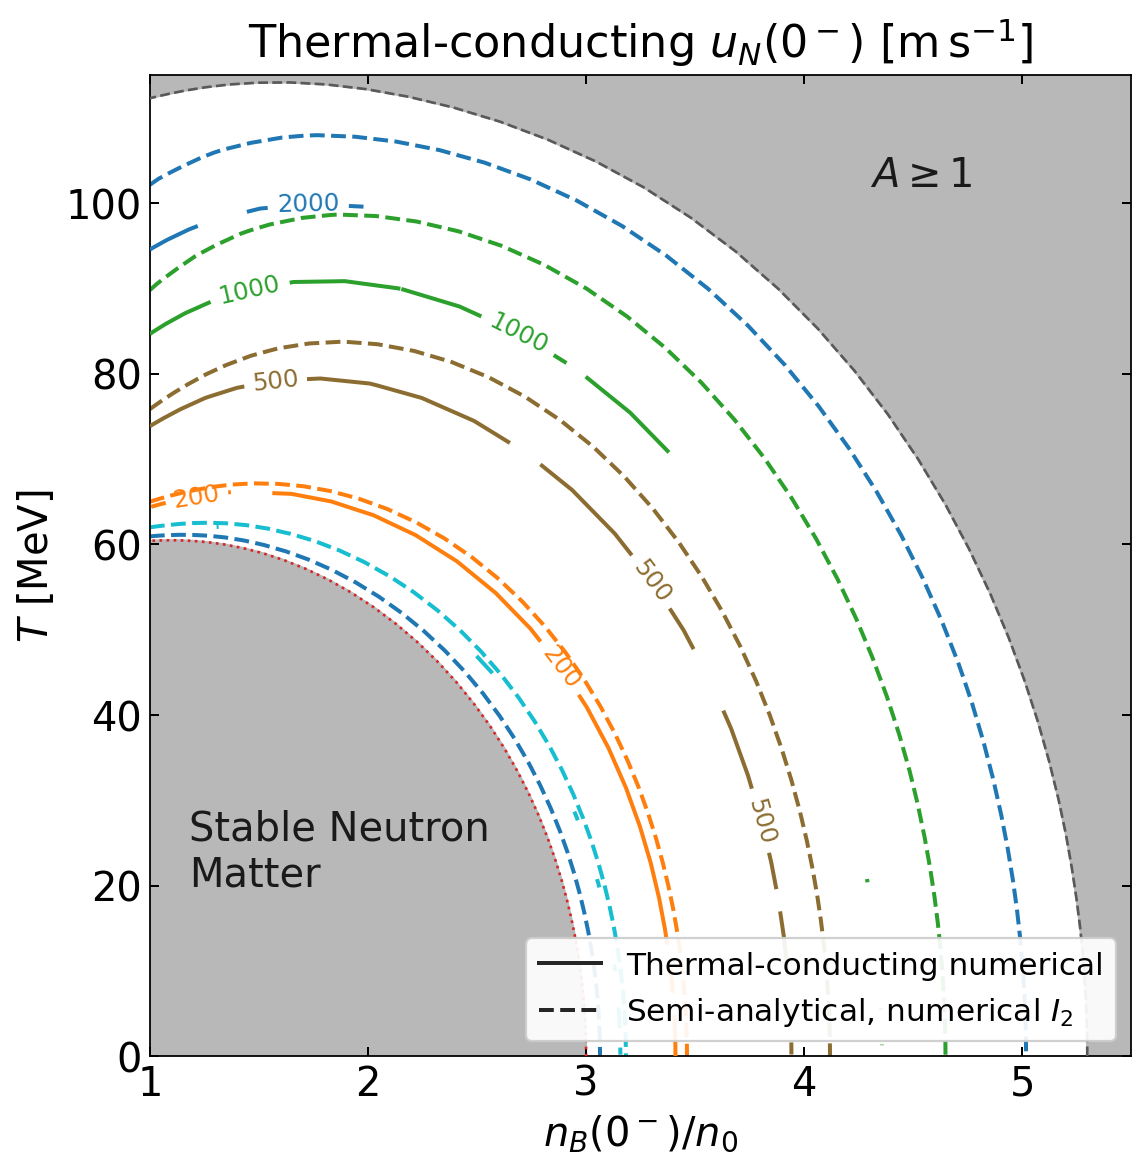

saved /Users/janshao/NSM_related/local_analysis_results/26SU-10/thermal-conducting-vs-semi-analytical-numerical-I2-contour.png
saved /Users/janshao/NSM_related/local_analysis_results/26SU-10/thermal-conducting-vs-semi-analytical-numerical-I2-contour.pdf


In [13]:
# Tunable plotting parameters
TC_CONTOUR_THERMAL_PAYLOAD_PATH = "new_paper_calculations/26-08-05/thermal-conducting-uN-T-nB-ray-grid.npy"
TC_CONTOUR_SEMI_ANALYTICAL_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
TC_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
TC_CONTOUR_FIGURE_DPI = 160
TC_CONTOUR_EXPORT_DPI = 220
TC_CONTOUR_CONSTRAINED_LAYOUT = True
TC_CONTOUR_BACKGROUND_COLOR = "white"
TC_CONTOUR_X_LIMITS = (1.0, 5.5)
TC_CONTOUR_Y_LIMITS_MEV = (0.0, 115.0)
TC_CONTOUR_X_SCALE = "linear"
TC_CONTOUR_Y_SCALE = "linear"
TC_CONTOUR_BOX_ASPECT = 1.0
TC_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
TC_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
TC_CONTOUR_LINE_WIDTH = 1.8
TC_CONTOUR_THERMAL_LINE_STYLE = "-"
TC_CONTOUR_SEMI_ANALYTICAL_LINE_STYLE = "--"
TC_CONTOUR_LABEL_FONT_SIZE = 11
TC_CONTOUR_LABEL_FORMAT = "%g"
TC_CONTOUR_LABEL_INLINE = True
TC_CONTOUR_LABEL_INLINE_SPACING = 4
TC_CONTOUR_SEMI_ANALYTICAL_LINE_ZORDER = 2
TC_CONTOUR_THERMAL_LINE_ZORDER = 3
TC_CONTOUR_GAP_SHADE_COLOR = "0.72"
TC_CONTOUR_A_SHADE_COLOR = "0.72"
TC_CONTOUR_SHADE_ALPHA = 1.0
TC_CONTOUR_SHADE_ZORDER = 0
TC_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
TC_CONTOUR_GAP_BOUNDARY_STYLE = ":"
TC_CONTOUR_GAP_BOUNDARY_WIDTH = 1.2
TC_CONTOUR_A_BOUNDARY_COLOR = "0.35"
TC_CONTOUR_A_BOUNDARY_STYLE = "--"
TC_CONTOUR_A_BOUNDARY_WIDTH = 1.2
TC_CONTOUR_BOUNDARY_ZORDER = 3
TC_CONTOUR_TITLE = r"Thermal-conducting $u_N(0^-)$ [$\mathrm{m\,s^{-1}}$]"
TC_CONTOUR_TITLE_FONT_SIZE = 20
TC_CONTOUR_TITLE_PAD = 8
TC_CONTOUR_X_LABEL = r"$n_B(0^-)/n_0$"
TC_CONTOUR_Y_LABEL = r"$T$ [MeV]"
TC_CONTOUR_AXIS_LABEL_FONT_SIZE = 18
TC_CONTOUR_TICK_LABEL_FONT_SIZE = 18
TC_CONTOUR_TICK_DIRECTION = "in"
TC_CONTOUR_TICKS_TOP = True
TC_CONTOUR_TICKS_RIGHT = True
TC_CONTOUR_TICK_LENGTH = 4.0
TC_CONTOUR_TICK_WIDTH = 0.9
TC_CONTOUR_SPINE_LINE_WIDTH = 0.8
TC_CONTOUR_A_TEXT = r"$A\geq 1$"
TC_CONTOUR_A_TEXT_POSITION = (4.3, 102.0)
TC_CONTOUR_GAP_TEXT = "Stable Neutron\nMatter"
TC_CONTOUR_GAP_TEXT_POSITION = (1.18, 20.0)
TC_CONTOUR_REGION_TEXT_COLOR = "0.10"
TC_CONTOUR_REGION_TEXT_FONT_SIZE = 18
TC_CONTOUR_TEXT_ZORDER = 4
TC_CONTOUR_LEGEND_LOCATION = "lower right"
TC_CONTOUR_LEGEND_FONT_SIZE = 14
TC_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
TC_CONTOUR_LEGEND_LINE_COLOR = "0.15"
TC_CONTOUR_OUTPUT_PNG = "local_analysis_results/26SU-10/thermal-conducting-vs-semi-analytical-numerical-I2-contour.png"
TC_CONTOUR_OUTPUT_PDF = "local_analysis_results/26SU-10/thermal-conducting-vs-semi-analytical-numerical-I2-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

tc_contour_root = Path.cwd()
tc_thermal_payload_path = tc_contour_root / TC_CONTOUR_THERMAL_PAYLOAD_PATH
tc_semi_payload_path = tc_contour_root / TC_CONTOUR_SEMI_ANALYTICAL_PAYLOAD_PATH
tc_thermal_payload = np.load(tc_thermal_payload_path, allow_pickle=True).item()
tc_semi_payload = np.load(tc_semi_payload_path, allow_pickle=True).item()

if tc_thermal_payload.get("numerical_closure") != "thermal_conducting_nK_jK_T":
    raise RuntimeError("Expected the thermal-conducting numerical payload")
if tc_semi_payload.get("velocity_closure") != "numerical_I2":
    raise RuntimeError("Expected the numerical-I2 semi-analytical payload")

tc_thermal_density = np.asarray(tc_thermal_payload["nB_grid_over_n0"], dtype=float)
tc_thermal_temperature = np.asarray(tc_thermal_payload["temperature_grid_MeV"], dtype=float)
tc_thermal_velocity = np.asarray(tc_thermal_payload["velocity_grid_m_s"], dtype=float)
tc_thermal_status = np.asarray(tc_thermal_payload["status_grid"])
tc_semi_density = np.asarray(tc_semi_payload["nB_grid_over_n0"], dtype=float)
tc_semi_temperature = np.asarray(tc_semi_payload["temperature_grid_MeV"], dtype=float)
tc_semi_velocity = np.asarray(tc_semi_payload["velocity_grid_m_s"], dtype=float)
tc_gap_density = np.asarray(tc_semi_payload["gap_boundary_nB_over_n0"], dtype=float)
tc_gap_temperature = np.asarray(tc_semi_payload["gap_boundary_temperature_MeV"], dtype=float)
tc_A_density = np.asarray(tc_semi_payload["A_boundary_nB_over_n0"], dtype=float)
tc_A_temperature = np.asarray(tc_semi_payload["A_boundary_temperature_MeV"], dtype=float)
tc_has_A_boundary = bool(tc_A_density.size and tc_A_temperature.size)
tc_thermal_mask = (~np.isfinite(tc_thermal_velocity)) | (tc_thermal_status != 0)
tc_thermal_velocity_masked = np.ma.array(tc_thermal_velocity, mask=tc_thermal_mask)
tc_semi_velocity_masked = np.ma.masked_invalid(tc_semi_velocity)

print(f"Thermal payload: {tc_thermal_payload_path}")
print(f"Semi-analytical payload: {tc_semi_payload_path}")
print(
    f"Finite thermal cells: {np.count_nonzero(~tc_thermal_mask)}"
    f"/{tc_thermal_velocity.size}"
)

tc_figure, tc_axis = plt.subplots(
    figsize=TC_CONTOUR_FIGURE_SIZE,
    dpi=TC_CONTOUR_FIGURE_DPI,
    constrained_layout=TC_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=TC_CONTOUR_BACKGROUND_COLOR,
)
tc_axis.set_facecolor(TC_CONTOUR_BACKGROUND_COLOR)

tc_gap_polygon_x = np.concatenate((
    tc_gap_density,
    (TC_CONTOUR_X_LIMITS[0], tc_gap_density[0]),
))
tc_gap_polygon_y = np.concatenate((
    tc_gap_temperature,
    (TC_CONTOUR_Y_LIMITS_MEV[0], TC_CONTOUR_Y_LIMITS_MEV[0]),
))
tc_axis.fill(
    tc_gap_polygon_x,
    tc_gap_polygon_y,
    color=TC_CONTOUR_GAP_SHADE_COLOR,
    alpha=TC_CONTOUR_SHADE_ALPHA,
    zorder=TC_CONTOUR_SHADE_ZORDER,
)
tc_axis.plot(
    tc_gap_density,
    tc_gap_temperature,
    color=TC_CONTOUR_GAP_BOUNDARY_COLOR,
    linestyle=TC_CONTOUR_GAP_BOUNDARY_STYLE,
    linewidth=TC_CONTOUR_GAP_BOUNDARY_WIDTH,
    zorder=TC_CONTOUR_BOUNDARY_ZORDER,
)

if tc_has_A_boundary:
    tc_A_polygon_x = np.concatenate((
        tc_A_density,
        (
            TC_CONTOUR_X_LIMITS[0],
            TC_CONTOUR_X_LIMITS[1],
            TC_CONTOUR_X_LIMITS[1],
            tc_A_density[0],
        ),
    ))
    tc_A_polygon_y = np.concatenate((
        tc_A_temperature,
        (
            TC_CONTOUR_Y_LIMITS_MEV[1],
            TC_CONTOUR_Y_LIMITS_MEV[1],
            TC_CONTOUR_Y_LIMITS_MEV[0],
            TC_CONTOUR_Y_LIMITS_MEV[0],
        ),
    ))
    tc_axis.fill(
        tc_A_polygon_x,
        tc_A_polygon_y,
        color=TC_CONTOUR_A_SHADE_COLOR,
        alpha=TC_CONTOUR_SHADE_ALPHA,
        zorder=TC_CONTOUR_SHADE_ZORDER,
    )
    tc_axis.plot(
        tc_A_density,
        tc_A_temperature,
        color=TC_CONTOUR_A_BOUNDARY_COLOR,
        linestyle=TC_CONTOUR_A_BOUNDARY_STYLE,
        linewidth=TC_CONTOUR_A_BOUNDARY_WIDTH,
        zorder=TC_CONTOUR_BOUNDARY_ZORDER,
    )

tc_semi_contours = tc_axis.contour(
    tc_semi_density,
    tc_semi_temperature,
    tc_semi_velocity_masked,
    levels=TC_CONTOUR_LEVELS_M_S,
    colors=TC_CONTOUR_COLORS,
    linewidths=TC_CONTOUR_LINE_WIDTH,
    linestyles=TC_CONTOUR_SEMI_ANALYTICAL_LINE_STYLE,
    zorder=TC_CONTOUR_SEMI_ANALYTICAL_LINE_ZORDER,
)
tc_thermal_contours = tc_axis.contour(
    tc_thermal_density,
    tc_thermal_temperature,
    tc_thermal_velocity_masked,
    levels=TC_CONTOUR_LEVELS_M_S,
    colors=TC_CONTOUR_COLORS,
    linewidths=TC_CONTOUR_LINE_WIDTH,
    linestyles=TC_CONTOUR_THERMAL_LINE_STYLE,
    zorder=TC_CONTOUR_THERMAL_LINE_ZORDER,
)
tc_axis.clabel(
    tc_thermal_contours,
    fontsize=TC_CONTOUR_LABEL_FONT_SIZE,
    fmt=TC_CONTOUR_LABEL_FORMAT,
    inline=TC_CONTOUR_LABEL_INLINE,
    inline_spacing=TC_CONTOUR_LABEL_INLINE_SPACING,
)

if tc_has_A_boundary:
    tc_axis.text(
        *TC_CONTOUR_A_TEXT_POSITION,
        TC_CONTOUR_A_TEXT,
        color=TC_CONTOUR_REGION_TEXT_COLOR,
        fontsize=TC_CONTOUR_REGION_TEXT_FONT_SIZE,
        zorder=TC_CONTOUR_TEXT_ZORDER,
    )
tc_axis.text(
    *TC_CONTOUR_GAP_TEXT_POSITION,
    TC_CONTOUR_GAP_TEXT,
    color=TC_CONTOUR_REGION_TEXT_COLOR,
    fontsize=TC_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=TC_CONTOUR_TEXT_ZORDER,
)

tc_axis.set_xlim(*TC_CONTOUR_X_LIMITS)
tc_axis.set_ylim(*TC_CONTOUR_Y_LIMITS_MEV)
tc_axis.set_xscale(TC_CONTOUR_X_SCALE)
tc_axis.set_yscale(TC_CONTOUR_Y_SCALE)
tc_axis.set_box_aspect(TC_CONTOUR_BOX_ASPECT)
tc_axis.set_title(
    TC_CONTOUR_TITLE,
    fontsize=TC_CONTOUR_TITLE_FONT_SIZE,
    pad=TC_CONTOUR_TITLE_PAD,
)
tc_axis.set_xlabel(TC_CONTOUR_X_LABEL, fontsize=TC_CONTOUR_AXIS_LABEL_FONT_SIZE)
tc_axis.set_ylabel(TC_CONTOUR_Y_LABEL, fontsize=TC_CONTOUR_AXIS_LABEL_FONT_SIZE)
tc_axis.tick_params(
    direction=TC_CONTOUR_TICK_DIRECTION,
    top=TC_CONTOUR_TICKS_TOP,
    right=TC_CONTOUR_TICKS_RIGHT,
    length=TC_CONTOUR_TICK_LENGTH,
    width=TC_CONTOUR_TICK_WIDTH,
    labelsize=TC_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for tc_spine in tc_axis.spines.values():
    tc_spine.set_linewidth(TC_CONTOUR_SPINE_LINE_WIDTH)

tc_legend_handles = [
    Line2D(
        (0.0,),
        (0.0,),
        color=TC_CONTOUR_LEGEND_LINE_COLOR,
        linestyle=TC_CONTOUR_THERMAL_LINE_STYLE,
        linewidth=TC_CONTOUR_LINE_WIDTH,
        label="Thermal-conducting numerical",
    ),
    Line2D(
        (0.0,),
        (0.0,),
        color=TC_CONTOUR_LEGEND_LINE_COLOR,
        linestyle=TC_CONTOUR_SEMI_ANALYTICAL_LINE_STYLE,
        linewidth=TC_CONTOUR_LINE_WIDTH,
        label=r"Semi-analytical, numerical $I_2$",
    ),
]
tc_axis.legend(
    handles=tc_legend_handles,
    loc=TC_CONTOUR_LEGEND_LOCATION,
    fontsize=TC_CONTOUR_LEGEND_FONT_SIZE,
    framealpha=TC_CONTOUR_LEGEND_FRAME_ALPHA,
)

tc_output_png = tc_contour_root / TC_CONTOUR_OUTPUT_PNG
tc_output_pdf = tc_contour_root / TC_CONTOUR_OUTPUT_PDF
tc_output_png.parent.mkdir(parents=True, exist_ok=True)
tc_figure.savefig(
    tc_output_png,
    dpi=TC_CONTOUR_EXPORT_DPI,
    facecolor=TC_CONTOUR_BACKGROUND_COLOR,
)
tc_figure.savefig(
    tc_output_pdf,
    facecolor=TC_CONTOUR_BACKGROUND_COLOR,
)
plt.show()
print(f"saved {tc_output_png.resolve()}")
print(f"saved {tc_output_pdf.resolve()}")


now the new workflow after group meeting today:
* (1) don't have to impose thermal conductivity because:
- no one have ever modeled the nuclear to quark matter thermal conductivity yet, so we cannot do anything across the boundary yet
- modeling the entire X>0 then would change the whole system of equations and would render our well developed analytical method, and it seems like a bad trade off
* (2) therefore, we don't have to impose T(0^+) = 0 exactly to make the solver behave well. 
* (3) whether to impose charge neutrality. the quark EoS in SQMsolver.py currently imposes charge neutrality, but our analytical derivations did not include that. this need more time/research on. probably I'd start a new chat specifically for this purpose.
* (4) from the first two points above, we need to work on studying how the three methods match each other:
- full analytical one, with a(0^+) neq A this time and choose a(0^+) s.t. T(0^+) is whatever numerical code uses, and \xi = -0.5 instead of 0
- semi-analytical one, just adjust \xi = -0.5, also this time, make T(0^+) a tunable parameter
- full numerical one, keep the thermal conducting code intact, but don't change that. from now on keep using the energy conserving code, but we choose a range of T(0^+) and see what matches the two analytical methods the best.

so read this, pull out a chronological workflow, tasks and break it down. do not change any code yet!
personally, I think a good starting point is to adjust the current code, analytical and numerical, so instead of taking a(0^+) as an input, take T(0^+) as input.

Your proposed starting point is right: make $T(0^+)$ the common physical control parameter for all three methods, and derive

$$
a(0^+) = \frac{n_K(0^+)}{n_B(0^+)}
$$

from the interface state. This prevents $a(0^+)$, $A$, and $T(0^+)$ from being mixed together as independent inputs.

**Scope Decisions**
- Freeze the thermal-conducting solver. Keep it intact as exploratory work, but remove it from the main comparison workflow.
- Do not require $T(0^+)=0$.
- Return to the ideal energy-conserving equations.
- Use $\xi=-0.5$ in both reduced analytical methods.
- Treat charge neutrality as a separate research project. For now, explicitly record the current neutrality assumptions in every comparison.

**Chronological Workflow**

1. **Define One Common Interface Contract**

   All three methods should take the same physical inputs:

   $$
   T_N,\quad n_B(0^-),\quad B^{1/4},\quad T_{Q*}\equiv T(0^+).
   $$

   They should all return:

   $$
   u_N,\quad j_B,\quad a(0^+),\quad A,\quad T_Q,
   $$

   plus the downstream and interface thermodynamic states.

   Here, $T_{Q*}$ is prescribed, $a(0^+)$ is derived, and $A$ remains the cold endpoint or interface-fraction ceiling.

2. **Update the Full Numerical Method First**

   Refactor `solve_front_energy_conserving_nK` so it can use fixed $T_{Q*}$ rather than fixed $a(0^+)$.

   The interface state should be reconstructed using the existing fixed-temperature closure already used by `uNmax`:

   $$
   T(0^+)=T_{Q*},
   $$

   together with the conserved energy and momentum fluxes. The resulting EOS state determines $n_K(0^+)$, $n_B(0^+)$, and therefore $a(0^+)$.

   I recommend temporarily preserving the old fixed-$a$ entry point for regression tests, rather than immediately deleting it.

3. **Consolidate `uNmax` and `energy_conserving_nK`**

   The two functions should no longer maintain separate implementations of the same fixed-temperature interface problem.

   The clean endpoint is:

   - `energy_conserving_nK` contains the authoritative $n_K,j_K$ BVP.
   - The interface closure can be selected by temperature or, temporarily, by legacy fixed $a$.
   - `uNmax` becomes a compatibility wrapper around the fixed-$T_{Q*}$ numerical solver, or is retired from new calculations.

4. **Update the Full Analytical Method**

   Use:

   $$
   \xi=-0.5,\qquad a(0^+)<A.
   $$

   Replace the current extreme-endothermic choice $a(0^+)=A$ with a temperature-controlled interface fraction:

   $$
   a(0^+)=a_{\mathrm{analytic}}(T_{Q*}).
   $$

   The important unresolved design choice is how this mapping is evaluated:

   - Pure closed-form mapping preserves a fully analytical method but retains the analytical EOS approximations.
   - Exact-EOS mapping is more consistent with the numerical solver but makes this branch partly semi-analytical.

   I recommend keeping the closed-form mapping for the “full analytical” branch and reporting its derived $a(0^+)$, so its approximation error remains measurable.

5. **Update the Semi-Analytical Method**

   Keep numerical $I_2$, but make $T_{Q*}$ tunable and set $\xi=-0.5$.

   Since this method already constructs the conserved thermodynamic trajectory, it should locate the point where

   $$
   T=T_{Q*}
   $$

   and evaluate the exact EOS fraction there:

   $$
   a(0^+)=\frac{n_K(T_{Q*})}{n_B(T_{Q*})}.
   $$

   It then numerically integrates $I_2$ from this interface point to downstream equilibrium.

6. **Build Pointwise Comparison Before New Contours**

   Test three representative physical locations:

   - Near the $\Delta h=0$ boundary.
   - In the middle of the allowed region.
   - Near the $A=1$ boundary, with a safety margin.

   At each point, scan several finite $T_{Q*}$ values and compare:

   $$
   u_N,\quad j_B,\quad a(0^+),\quad A,\quad T_Q.
   $$

   Primary comparison metrics:

   $$
   \frac{u_{\mathrm{analytical}}-u_{\mathrm{numerical}}}
        {u_{\mathrm{numerical}}},
   \qquad
   \frac{u_{\mathrm{semi}}-u_{\mathrm{numerical}}}
        {u_{\mathrm{numerical}}}.
   $$

   Also compare the full numerical $a'$-versus-$a$ projection against the $\xi=-0.5$ reduced profile.

7. **Choose the Useful $T_{Q*}$ Range**

   Do not immediately commit to one value such as $0.01$ or $0.5$ MeV.

   First perform a small finite-temperature sensitivity scan. The useful range should satisfy:

   - The numerical solution is unique and stable.
   - The result is insensitive to mesh and continuation details.
   - The analytical and semi-analytical branches approach the numerical result smoothly.
   - $T_{Q*}$ is small compared with the downstream temperature when that approximation is required.

8. **Only Then Generate Contours**

   Once pointwise behavior is clean:

   - Use one shared physical $(T_N,n_B(0^-))$ mesh.
   - Run several selected $T_{Q*}$ values.
   - Store all three velocities and their derived $a(0^+)$ on the same grid.
   - Plot analytical, semi-analytical, and numerical contours together.
   - Add relative-error maps rather than judging agreement only by overlaid lines.

9. **Separate Charge-Neutrality Study**

   Handle this in a separate task. It should determine:

   - What neutrality constraint `SQMsolver.py` actually imposes.
   - Whether the analytical variables implicitly assume a non-neutral quark layer.
   - Whether local or global neutrality is physically appropriate across the reaction zone.
   - Which analytical formulas must be rederived if neutrality is enforced.

   Until that is resolved, the three-method comparison is a mathematical consistency study, not yet the final physical result.

The first implementation unit should therefore be: **introduce a shared fixed-$T_{Q*}$ interface closure and make the authoritative energy-conserving $n_K,j_K$ solver derive $a(0^+)$ from it.**

## Preflight comparison of the outer analytical boundaries

The previous diagnostic evaluated a (16\times10) rectangular field even though the quantity of interest is a one-dimensional boundary. It also treated every failed semi-analytical evaluation as though it were an (A\geq1) state, which mixed the composition ceiling with unrelated reachability and root failures.

This replacement follows the geometry used by `26-08-07` directly. It resolves the full-analytical outer boundary on eight hidden elliptical rays, then resolves the semi-analytical outer boundary on those same rays. The full method normally ends at (A=1); at fixed (T(0^+)), the semi-analytical conserved trajectory may instead reach its interface-temperature accessibility edge while (A<1). Both boundary kinds are preserved rather than conflated. The result contains (8+8=16) resolved boundary points, with internal probes used only for bracketing and refinement. No full numerical BVP is run in this preflight because `uNmax` has no independent (A)-boundary definition.


In [3]:
# Tunable diagnostic parameters
A_BOUNDARY_T_0PLUS_MEV = 4.0
A_BOUNDARY_XI = -0.5
A_BOUNDARY_DENSITY_MIN_OVER_N0 = 1.0
A_BOUNDARY_DENSITY_MAX_OVER_N0 = 10.0
A_BOUNDARY_T_MIN_MEV = 1.0e-2
A_BOUNDARY_T_MAX_MEV = 200.0
A_BOUNDARY_RAY_COUNT = 8
A_BOUNDARY_ENDPOINT_PROBE_COUNT = 11
A_BOUNDARY_RAY_PROBE_COUNT = 9
A_BOUNDARY_BISECTION_STEPS = 8
A_BOUNDARY_GAP_BISECTION_STEPS = 20
A_BOUNDARY_ANGULAR_BUFFER_FRACTION = 0.08
A_BOUNDARY_WORKERS = 8
A_BOUNDARY_UPB = 5000
A_BOUNDARY_FORCE_RECOMPUTE = False
A_BOUNDARY_CACHE_PATH = Path(
    "local_analysis_results/26SU-10/A-boundary-preflight-16-points.npy"
)

from concurrent.futures import ThreadPoolExecutor, as_completed
import importlib.util
from tqdm.auto import tqdm

_A_BOUNDARY_ENGINE_PATH = Path(
    "new_paper_calculations/26-08-07/_analytic_ray_grid.py"
).resolve()
_A_BOUNDARY_SPEC = importlib.util.spec_from_file_location(
    "benchmark_260807_ray_grid", _A_BOUNDARY_ENGINE_PATH
)
a_boundary_ray_grid = importlib.util.module_from_spec(_A_BOUNDARY_SPEC)
_A_BOUNDARY_SPEC.loader.exec_module(a_boundary_ray_grid)
a_boundary_ray_grid.BOUNDARY_T_0PLUS_MEV = A_BOUNDARY_T_0PLUS_MEV


def _solve_full_A_boundary():
    transform = a_boundary_ray_grid.RayTransform(
        density_origin_over_n0=A_BOUNDARY_DENSITY_MIN_OVER_N0,
        density_scale_over_n0=(
            A_BOUNDARY_DENSITY_MAX_OVER_N0 - A_BOUNDARY_DENSITY_MIN_OVER_N0
        ),
        temperature_scale_MeV=A_BOUNDARY_T_MAX_MEV,
    )
    with ThreadPoolExecutor(max_workers=A_BOUNDARY_WORKERS) as executor:
        boundary = a_boundary_ray_grid.solve_boundary_curves(
            transform=transform,
            theta_count=A_BOUNDARY_RAY_COUNT,
            density_min_over_n0=A_BOUNDARY_DENSITY_MIN_OVER_N0,
            density_max_over_n0=A_BOUNDARY_DENSITY_MAX_OVER_N0,
            temperature_min_MeV=A_BOUNDARY_T_MIN_MEV,
            temperature_max_MeV=A_BOUNDARY_T_MAX_MEV,
            n0=N0_MEV3,
            B14=B14_MEV,
            xi=A_BOUNDARY_XI,
            ms=MS_MEV,
            nm_type=NM_TYPE,
            upB=A_BOUNDARY_UPB,
            interface_fraction_mode="fixed_T_0plus",
            velocity_closure="closed_form",
            endpoint_probe_count=A_BOUNDARY_ENDPOINT_PROBE_COUNT,
            ray_probe_count=A_BOUNDARY_RAY_PROBE_COUNT,
            bisection_steps=A_BOUNDARY_BISECTION_STEPS,
            gap_bisection_steps=A_BOUNDARY_GAP_BISECTION_STEPS,
            angular_buffer_fraction=A_BOUNDARY_ANGULAR_BUFFER_FRACTION,
            progress_factory=lambda **kwargs: tqdm(leave=False, **kwargs),
            executor=executor,
        )
    return transform, boundary


def _solve_one_semi_A_ray(index, theta, rho_inner, rho_outer_hint, transform):
    _, rho_window_max = a_boundary_ray_grid._ray_rho_bounds(
        transform=transform,
        theta_rad=theta,
        density_max_over_n0=A_BOUNDARY_DENSITY_MAX_OVER_N0,
        temperature_min_MeV=A_BOUNDARY_T_MIN_MEV,
        temperature_max_MeV=A_BOUNDARY_T_MAX_MEV,
    )
    rho_start = float(rho_inner) + 1.0e-10
    probes = np.linspace(
        rho_start,
        float(rho_window_max),
        A_BOUNDARY_RAY_PROBE_COUNT,
    )
    try:
        record = a_boundary_ray_grid.solve_A_transition_on_path(
            coordinates=probes,
            physical_coordinates=lambda rho: tuple(
                float(value) for value in transform.to_physical(rho, theta)
            ),
            n0=N0_MEV3,
            B14=B14_MEV,
            xi=A_BOUNDARY_XI,
            ms=MS_MEV,
            nm_type=NM_TYPE,
            upB=A_BOUNDARY_UPB,
            interface_fraction_mode="fixed_T_0plus",
            velocity_closure="numerical_I2",
            label="semi_analytic_A_elliptical_ray",
            endpoint_hint=rho_outer_hint.get("endpoint_solution"),
            muB_hint=float(rho_outer_hint.get("muB_0minus_MeV", 1100.0)),
            bisection_steps=A_BOUNDARY_BISECTION_STEPS,
            allow_missing=False,
        )
        record.update(
            {
                "ray_index": int(index),
                "rho": float(record["coordinate"]),
                "theta_rad": float(theta),
                "theta_deg": float(np.degrees(theta)),
                "diagnostic_status": "success",
            }
        )
        return record
    except Exception as exc:
        return {
            "ray_index": int(index),
            "rho": np.nan,
            "theta_rad": float(theta),
            "theta_deg": float(np.degrees(theta)),
            "nB_over_n0": np.nan,
            "T_MeV": np.nan,
            "diagnostic_status": "failed",
            "message": str(exc),
        }


def _solve_semi_A_boundary(transform, full_boundary):
    theta_axis = np.asarray(full_boundary["theta_axis_rad"], dtype=float)
    rho_inner = np.asarray(full_boundary["rho_inner"], dtype=float)
    full_records = list(full_boundary["A_records"])
    rows = [None] * theta_axis.size
    with ThreadPoolExecutor(max_workers=A_BOUNDARY_WORKERS) as executor:
        futures = {
            executor.submit(
                _solve_one_semi_A_ray,
                index,
                float(theta_axis[index]),
                float(rho_inner[index]),
                full_records[index],
                transform,
            ): index
            for index in range(theta_axis.size)
        }
        with tqdm(
            total=theta_axis.size,
            desc="Semi-analytical A boundary",
            unit="ray",
            leave=False,
        ) as progress:
            for future in as_completed(futures):
                index = futures[future]
                rows[index] = future.result()
                progress.update(1)
    return rows


A_BOUNDARY_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
if A_BOUNDARY_FORCE_RECOMPUTE or not A_BOUNDARY_CACHE_PATH.exists():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _a_boundary_transform, _a_boundary_full = _solve_full_A_boundary()
        _a_boundary_semi = _solve_semi_A_boundary(
            _a_boundary_transform, _a_boundary_full
        )
    a_boundary_diagnostic = {
        "T_0plus_MeV": A_BOUNDARY_T_0PLUS_MEV,
        "xi": A_BOUNDARY_XI,
        "ray_count_per_method": A_BOUNDARY_RAY_COUNT,
        "reported_boundary_point_count": 2 * A_BOUNDARY_RAY_COUNT,
        "window": {
            "density_min_over_n0": A_BOUNDARY_DENSITY_MIN_OVER_N0,
            "density_max_over_n0": A_BOUNDARY_DENSITY_MAX_OVER_N0,
            "T_min_MeV": A_BOUNDARY_T_MIN_MEV,
            "T_max_MeV": A_BOUNDARY_T_MAX_MEV,
        },
        "full_boundary": _a_boundary_full,
        "semi_A_records": _a_boundary_semi,
    }
    np.save(A_BOUNDARY_CACHE_PATH, a_boundary_diagnostic, allow_pickle=True)
    print(f"Saved {A_BOUNDARY_CACHE_PATH}")
else:
    a_boundary_diagnostic = np.load(
        A_BOUNDARY_CACHE_PATH, allow_pickle=True
    ).item()
    print(f"Loaded {A_BOUNDARY_CACHE_PATH}")

_a_full_records = [
    row
    for row in a_boundary_diagnostic["full_boundary"]["A_records"]
    if row.get("boundary_kind") == "A_equals_one"
]
_a_semi_records = [
    row
    for row in a_boundary_diagnostic["semi_A_records"]
    if row.get("diagnostic_status") == "success"
]
_a_semi_failures = [
    row
    for row in a_boundary_diagnostic["semi_A_records"]
    if row.get("diagnostic_status") != "success"
]
print(
    f"Resolved A=1 points: full analytical {_a_full_records.__len__()}/"
    f"{A_BOUNDARY_RAY_COUNT}, semi-analytical {_a_semi_records.__len__()}/"
    f"{A_BOUNDARY_RAY_COUNT}; total reported boundary points "
    f"{len(_a_full_records) + len(_a_semi_records)}."
)
if _a_semi_failures:
    print("Semi-analytical rays without a clean A transition:")
    for _row in _a_semi_failures:
        print(
            f"  ray {_row['ray_index']}: theta={_row['theta_deg']:.2f} deg; "
            f"{_row.get('message', 'unknown failure')}"
        )


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RuntimeError: gap_bottom_endpoint: Delta h residual did not close

In [ ]:
# Tunable plotting parameters
FIGURE_SIZE = (15.5, 6.5)
FIGURE_DPI = 140
TITLE_FONT_SIZE = 17
AXIS_LABEL_FONT_SIZE = 15
TICK_LABEL_FONT_SIZE = 12
LEGEND_FONT_SIZE = 11
ANNOTATION_FONT_SIZE = 11
FULL_BOUNDARY_COLOR = "crimson"
SEMI_BOUNDARY_COLOR = "deepskyblue"
GAP_BOUNDARY_COLOR = "0.25"
FULL_BOUNDARY_LINE_STYLE = "-"
SEMI_BOUNDARY_LINE_STYLE = "--"
GAP_BOUNDARY_LINE_STYLE = ":"
BOUNDARY_LINE_WIDTH = 2.5
RAW_POINT_MARKER_SIZE = 7.0
FULL_POINT_MARKER = "o"
SEMI_POINT_MARKER = "s"
STABLE_REGION_COLOR = "0.75"
EXCLUDED_REGION_COLOR = "0.88"
DISAGREEMENT_REGION_COLOR = "mediumpurple"
REGION_ALPHA = 0.55
DISAGREEMENT_ALPHA = 0.28
DIFFERENCE_LINE_COLOR = "purple"
DIFFERENCE_LINE_WIDTH = 2.2
ZERO_LINE_COLOR = "black"
ZERO_LINE_STYLE = "--"
ZERO_LINE_WIDTH = 1.0
GRID_COLOR = "0.75"
GRID_ALPHA = 0.30
GRID_LINE_WIDTH = 0.8
LEGEND_LOCATION = "best"
X_AXIS_LABEL = r"$n_B(0^-)/n_0$"
Y_AXIS_LABEL = r"$T(0^-)$ [MeV]"
DIFFERENCE_Y_LABEL = r"$[n_{B,\mathrm{out}}^{\rm semi}-n_{B,\mathrm{out}}^{\rm full}]/n_0$"
TEMPERATURE_AXIS_SCALE = "linear"
INTERPOLATION_POINT_COUNT = 240
SUBPLOT_WIDTH_RATIOS = (1.25, 1.0)
LAYOUT_PAD = 1.2


def _clean_boundary_curve(records, required_kind=None):
    points = []
    for row in records:
        if required_kind is not None and row.get("boundary_kind") != required_kind:
            continue
        density = float(row.get("nB_over_n0", np.nan))
        temperature = float(row.get("T_MeV", np.nan))
        if np.isfinite(density) and np.isfinite(temperature):
            points.append((temperature, density))
    if not points:
        return np.array([]), np.array([])
    points = np.asarray(points, dtype=float)
    points = points[np.argsort(points[:, 0])]
    temperatures, unique_indices = np.unique(points[:, 0], return_index=True)
    return points[unique_indices, 1], temperatures


_full_nB, _full_T = _clean_boundary_curve(
    a_boundary_diagnostic["full_boundary"]["A_records"], "A_equals_one"
)
_semi_nB, _semi_T = _clean_boundary_curve(
    a_boundary_diagnostic["semi_A_records"]
)
_gap_nB, _gap_T = _clean_boundary_curve(
    a_boundary_diagnostic["full_boundary"]["gap_curve_records"],
    "Delta_h_equals_zero",
)
_window = a_boundary_diagnostic["window"]

_figure, (_domain_axis, _difference_axis) = plt.subplots(
    1,
    2,
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    gridspec_kw={"width_ratios": SUBPLOT_WIDTH_RATIOS},
)

if _gap_T.size >= 2:
    _domain_axis.fill_betweenx(
        _gap_T,
        _window["density_min_over_n0"],
        _gap_nB,
        color=STABLE_REGION_COLOR,
        alpha=REGION_ALPHA,
        label=r"no finite-velocity endpoint",
    )
    _domain_axis.plot(
        _gap_nB,
        _gap_T,
        color=GAP_BOUNDARY_COLOR,
        linestyle=GAP_BOUNDARY_LINE_STYLE,
        linewidth=BOUNDARY_LINE_WIDTH,
        label=r"$\Delta h=0$",
    )

if _full_T.size >= 2 and _semi_T.size >= 2:
    _common_T_min = max(float(_full_T.min()), float(_semi_T.min()))
    _common_T_max = min(float(_full_T.max()), float(_semi_T.max()))
    _common_T = np.linspace(
        _common_T_min, _common_T_max, INTERPOLATION_POINT_COUNT
    )
    _full_interp = np.interp(_common_T, _full_T, _full_nB)
    _semi_interp = np.interp(_common_T, _semi_T, _semi_nB)
    _common_outer = np.minimum(_full_interp, _semi_interp)
    _domain_axis.fill_betweenx(
        _common_T,
        _common_outer,
        _window["density_max_over_n0"],
        color=EXCLUDED_REGION_COLOR,
        alpha=REGION_ALPHA,
        label=r"excluded by at least one method",
    )
    _domain_axis.fill_betweenx(
        _common_T,
        np.minimum(_full_interp, _semi_interp),
        np.maximum(_full_interp, _semi_interp),
        color=DISAGREEMENT_REGION_COLOR,
        alpha=DISAGREEMENT_ALPHA,
        label="boundary disagreement",
    )
    _boundary_difference = _semi_interp - _full_interp
    _difference_axis.plot(
        _boundary_difference,
        _common_T,
        color=DIFFERENCE_LINE_COLOR,
        linewidth=DIFFERENCE_LINE_WIDTH,
    )
    _difference_axis.fill_betweenx(
        _common_T,
        0.0,
        _boundary_difference,
        color=DISAGREEMENT_REGION_COLOR,
        alpha=DISAGREEMENT_ALPHA,
    )
    _difference_axis.axvline(
        0.0,
        color=ZERO_LINE_COLOR,
        linestyle=ZERO_LINE_STYLE,
        linewidth=ZERO_LINE_WIDTH,
    )
else:
    _difference_axis.text(
        0.5,
        0.5,
        "A clean boundary was not resolved\nfor both methods on at least two rays.",
        transform=_difference_axis.transAxes,
        ha="center",
        va="center",
        fontsize=ANNOTATION_FONT_SIZE,
    )

if _full_T.size:
    _domain_axis.plot(
        _full_nB,
        _full_T,
        color=FULL_BOUNDARY_COLOR,
        linestyle=FULL_BOUNDARY_LINE_STYLE,
        linewidth=BOUNDARY_LINE_WIDTH,
        marker=FULL_POINT_MARKER,
        markersize=RAW_POINT_MARKER_SIZE,
        label=r"full analytical $A=1$",
    )
if _semi_T.size:
    _domain_axis.plot(
        _semi_nB,
        _semi_T,
        color=SEMI_BOUNDARY_COLOR,
        linestyle=SEMI_BOUNDARY_LINE_STYLE,
        linewidth=BOUNDARY_LINE_WIDTH,
        marker=SEMI_POINT_MARKER,
        markersize=RAW_POINT_MARKER_SIZE,
        label=r"semi-analytical outer edge",
    )

_domain_axis.set_title(
    rf"Outer-domain comparison at $T(0^+)={a_boundary_diagnostic['T_0plus_MeV']:g}$ MeV, "
    rf"$\xi={a_boundary_diagnostic['xi']:g}$",
    fontsize=TITLE_FONT_SIZE,
)
_domain_axis.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
_domain_axis.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
_domain_axis.set_xlim(
    _window["density_min_over_n0"], _window["density_max_over_n0"]
)
_domain_axis.set_ylim(_window["T_min_MeV"], _window["T_max_MeV"])
_domain_axis.set_yscale(TEMPERATURE_AXIS_SCALE)
_domain_axis.tick_params(labelsize=TICK_LABEL_FONT_SIZE)
_domain_axis.grid(
    color=GRID_COLOR,
    alpha=GRID_ALPHA,
    linewidth=GRID_LINE_WIDTH,
)
_domain_axis.legend(fontsize=LEGEND_FONT_SIZE, loc=LEGEND_LOCATION)

_difference_axis.set_title(
    "Semi-analytical minus full-analytical outer edge",
    fontsize=TITLE_FONT_SIZE,
)
_difference_axis.set_xlabel(DIFFERENCE_Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
_difference_axis.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
_difference_axis.set_ylim(_window["T_min_MeV"], _window["T_max_MeV"])
_difference_axis.set_yscale(TEMPERATURE_AXIS_SCALE)
_difference_axis.tick_params(labelsize=TICK_LABEL_FONT_SIZE)
_difference_axis.grid(
    color=GRID_COLOR,
    alpha=GRID_ALPHA,
    linewidth=GRID_LINE_WIDTH,
)

_figure.tight_layout(pad=LAYOUT_PAD)
plt.show()


NameError: name 'a_boundary_diagnostic' is not defined